# NHL Hockey Project

## 1. Business Understanding (BU)

This project explores how historical NHL data can support pre-season projections and risk assessment. Its current scope is to prepare and assess candidate data for three prediction tasks for the 2010 season.

### Analysis of Requirements with the End User

- **Business context:** Use machine-learning models to make predictions related to ice hockey.
- **Available data:** 22 historical NHL-related datasets covering 1909-2009.
- **Prediction timing:** Make predictions using only information available the day before the target season's first game.
- **Historical challenges:** Account for league expansion, structural changes, and evolving rules and points systems.
- **Tasks in the current project:**

| Task | Target | Unit |
|---|---|---|
| (a) | Final regular-season league ranking | team-season |
| (b) | Coach change during the season | team-season |
| (c) | Regular-season penalty minutes (PIM) | player-season |

### Definition of Business Goals

**Goal 1 - Standing projections**
- Predict each team's final regular-season league ranking and estimate competitiveness using historical standings, player statistics, and goaltending performance where useful.

**Goal 2 - Coaching risk assessment**
- Predict which teams change their head coach during the season and identify associated risk factors, such as underperformance and prior coaching turnover.

**Goal 3 - Player penalty-minute projection**
- Predict regular-season PIM for each player-season, using earlier player history and other pre-season information where available.

**Expected business value:** Support pre-season strategic planning, competitive assessment, and coaching-related risk management.

### Translation of Business Goals into Data-Mining Goals

**Goal 1 - Standing projections**
- **Data-mining task:** Ranking prediction or regression to a league-wide rank measure, built from points percentage because the source rank is divisional/conference-based.
- **Evaluation:** Use within-season Spearman correlation as the primary ranking measure and compare against the historical persistence baseline; rank MAE may be reported as a complementary measure. No fitted ranking model is evaluated in this notebook.

**Goal 2 - Coaching risk assessment**
- **Data-mining task:** Binary classification of whether a team changes its coach during the target season.
- **Evaluation:** Report average precision alongside precision, recall, F1-score, and ROC-AUC; compare with the event-rate baseline. The class imbalance makes accuracy insufficient on its own.

**Goal 3 - Player penalty-minute projection**
- **Data-mining task:** Regression of player-season PIM, with per-game rates considered during feature and target analysis.
- **Evaluation:** Use mean absolute error (MAE) and bias, and compare with simple historical baselines. The notebook's strongest reported baseline has MAE of about 19.9 minutes.

**Key constraint:** Every predictor must be available before the first game of the target season to prevent data leakage. The available data ends in 2009, so it supports historical analysis and proposed 2010 predictions but cannot validate those predictions without 2010 outcomes.

### Notebook setup

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score, average_precision_score
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

DATA_DIR = "data/"
TARGET_SEASON = 2010
ERA_A = 1995
ERA_B = 1990
ERA_C = 1995
MAX_GAP = 2
EXPANSION_YEAR = 1967
FIRST_POST_LOCKOUT = 2005

In [3]:
def nhl(df):
    return df[df["lgID"] == "NHL"].copy() if "lgID" in df.columns else df.copy()

def to_num(df, cols):
    for c in cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    return df

def add_lags(df, entity, cols, lags=(1, 2, 3), time="year"):
    df = df.sort_values([entity, time]).copy()
    g = df.groupby(entity)
    new = {}
    for k in lags:
        for c in cols:
            new[f"{c}_lag{k}"] = g[c].shift(k)
        new[f"{time}_gap{k}"] = df[time] - g[time].shift(k)
    return pd.concat([df, pd.DataFrame(new, index=df.index)], axis=1)

def spearman(x, y):
    m = x.notna() & y.notna()
    if m.sum() < 5 or x[m].nunique() < 2 or y[m].nunique() < 2:
        return np.nan
    return stats.spearmanr(x[m], y[m])[0]

def spearman_table(df, features, target, r_min=0.10, alpha=0.05):
    rows = []
    for f in features:
        m = df[f].notna() & df[target].notna()
        if m.sum() < 30 or df.loc[m, f].nunique() < 2:
            continue
        r, p = stats.spearmanr(df.loc[m, f], df.loc[m, target])
        rows.append({"feature": f, "n": int(m.sum()), "spearman": round(r, 3), "p_value": round(p, 4),
                     "decision": "keep" if (abs(r) >= r_min and p < alpha) else "drop"})
    return pd.DataFrame(rows).sort_values("spearman", key=lambda s: s.abs(), ascending=False).reset_index(drop=True)

def auc_interval(y, x, n_boot=300, seed=0):
    rng = np.random.default_rng(seed)
    n = len(y)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if y[idx].min() == y[idx].max():
            continue
        vals.append(roc_auc_score(y[idx], x[idx]))
    return np.percentile(vals, [2.5, 97.5])

def auc_table(df, features, target):
    rows = []
    y_all = df[target].astype(int)
    for f in features:
        m = df[f].notna()
        if m.sum() < 50 or y_all[m].nunique() < 2:
            continue
        y = y_all[m].to_numpy()
        x = df.loc[m, f].astype(float).to_numpy()
        auc = roc_auc_score(y, x)
        lo, hi = auc_interval(y, x)
        rows.append({"feature": f, "n": int(m.sum()), "auc": round(auc, 3), "ci_low": round(lo, 3), "ci_high": round(hi, 3),
                     "direction": "higher, more changes" if auc >= 0.5 else "higher, fewer changes",
                     "avg_precision": round(average_precision_score(y, x if auc >= 0.5 else -x), 3),
                     "decision": "keep" if (lo > 0.5 or hi < 0.5) else "drop"})
    out = pd.DataFrame(rows)
    out["strength"] = (out["auc"] - 0.5).abs()
    return out.sort_values("strength", ascending=False).drop(columns="strength").reset_index(drop=True)

def mark_events(ax):
    ax.axvline(EXPANSION_YEAR, color="grey", ls="--", lw=1)
    ax.axvline(FIRST_POST_LOCKOUT, color="red", ls=":", lw=1)

## 2. Data Understanding (DU)

### 2.1 Audit

Checks done before any plot: that every file has the columns the analysis needs, which leagues are present, and whether the keys are unique.

In [4]:
datasets = {}
for f in sorted(os.listdir(DATA_DIR)):
    if f.endswith(".csv"):
        datasets[f[:-4]] = pd.read_csv(os.path.join(DATA_DIR, f), low_memory=False)

overview = []
for name, df in datasets.items():
    yr = df["year"] if "year" in df.columns else pd.Series(dtype=float)
    overview.append({"dataset": name, "rows": len(df), "cols": df.shape[1],
                     "year_min": yr.min() if len(yr) else np.nan, "year_max": yr.max() if len(yr) else np.nan})
pd.DataFrame(overview).sort_values("rows", ascending=False).reset_index(drop=True)

,dataset,rows,cols,year_min,year_max
0,Scoring,43848,31,1909.0,2009.0
1,TeamVsTeam,23862,8,1909.0,2009.0
2,Master,7469,31,NaN,NaN
3,Goalies,4096,23,1909.0,2009.0
4,AwardsPlayers,2021,6,1917.0,2009.0
5,Coaches,1741,14,1909.0,2009.0
6,ScoringShootout,1487,7,2005.0,2009.0
7,TeamSplits,1459,43,1909.0,2009.0
8,Teams,1459,27,1909.0,2009.0
9,TeamsPost,895,17,1913.0,2009.0


In [5]:
EXPECTED = {
    "Teams": ["year", "lgID", "tmID", "franchID", "divID", "rank", "playoff", "G", "W", "L", "T", "OTL", "Pts", "GF", "GA", "PIM", "PPG", "PPC", "PKG", "PKC"],
    "Coaches": ["coachID", "year", "tmID", "lgID", "stint", "g", "w", "l", "t"],
    "Scoring": ["playerID", "year", "stint", "tmID", "lgID", "pos", "GP", "G", "A", "Pts", "PIM"],
    "Master": ["playerID", "coachID", "birthYear", "height", "weight", "shootCatch", "pos"],
    "Goalies": ["playerID", "year", "stint", "tmID", "GP", "Min", "GA", "SA"],
    "TeamSplits": ["year", "tmID", "hW", "hL", "rW", "rL"],
    "TeamsPost": ["year", "tmID", "G", "W"],
    "AwardsCoaches": ["coachID", "award", "year"],
    "AwardsPlayers": ["playerID", "award", "year"],
}
for name, cols in EXPECTED.items():
    missing = [c for c in cols if c not in datasets[name].columns] if name in datasets else "file not found"
    print(f"{name:14s}", "ok" if missing == [] else missing)

lg = pd.DataFrame({n: datasets[n]["lgID"].value_counts() for n in ["Teams", "Scoring", "Coaches", "Goalies"]}).fillna(0).astype(int)
display(lg)
for label, (df, key) in {"Teams (year, tmID)": (nhl(datasets["Teams"]), ["year", "tmID"]),
                         "Scoring (playerID, year, stint)": (nhl(datasets["Scoring"]), ["playerID", "year", "stint"]),
                         "Coaches (coachID, year, tmID, stint)": (nhl(datasets["Coaches"]), ["coachID", "year", "tmID", "stint"])}.items():
    print(f"{label:40s} duplicated keys: {df.duplicated(key).sum()}")
print("\nTeams.playoff values:", datasets["Teams"]["playoff"].value_counts(dropna=False).to_dict())

Teams          ok
Coaches        ok
Scoring        ok
Master         ok
Goalies        ok
TeamSplits     ok
TeamsPost      ok
AwardsCoaches  ok
AwardsPlayers  ok


,Teams,Scoring,Coaches,Goalies
lgID,,,,
NHL,1265,40101,1522,3678
WHA,84,2436,111,259
NHA,45,586,43,75
PCHA,41,404,41,47
WCHL,24,321,24,37


Teams (year, tmID)                       duplicated keys: 0
Scoring (playerID, year, stint)          duplicated keys: 0
Coaches (coachID, year, tmID, stint)     duplicated keys: 0

Teams.playoff values: {nan: 555, 'CQF': 128, 'SF': 112, 'DSF': 96, 'SC': 95, 'F': 95, 'QF': 88, 'CSF': 64, 'CF': 56, 'DF': 48, 'PRE': 36, 'AVQF': 23, 'AVSF': 13, 'NHLF': 8, 'PF': 7, 'AVC': 7, 'AVF': 7, 'WF': 5, 'NHAF': 3, 'WSF': 3, 'SCSF': 3, 'AVPRE': 3, 'ND': 2, 'LCS': 1, 'WCS': 1}


### Findings

- The data covers 1909-2009, so the target season (2010) is not in it. Every model has to extrapolate one season ahead.
- Four other leagues are mixed with the NHL: WHA, NHA, PCHA and WCHL. They account for 194 of 1,459 rows in `Teams` and 3,747 of 43,848 in `Scoring`. Keeping them would pollute player histories, league-wide rankings and coach tenures, so everything below uses `lgID == "NHL"`.
- Keys are unique after the league filter: one row per team-year in `Teams`, one per player-year-stint in `Scoring`. A player traded during a season has several rows, so player PIM must be summed over stints.
- `Teams.playoff` stores the round reached (`CQF`, `QF`, `SF`, `DSF`, `CSF`, `DF`, `CF`, `F`, `SC`) and is empty for teams that missed the playoffs. A team-season "made the playoffs" flag is therefore the non-empty test.
- Several files are marginal in size or period: `ScoringShootout` and `GoaliesShootout` only exist for 2005-2009, `ScoringSup` for 1987-1990 (137 rows), `AwardsMisc` has 120 rows and `AwardsCoaches` 75.

### 2.2 Coverage by variable and year

Table-level missing percentages are misleading: many variables were simply not recorded in early decades. The heatmaps show the share of non-empty values by column and 5-year period, and the table gives the first year each column is at least 90% filled.

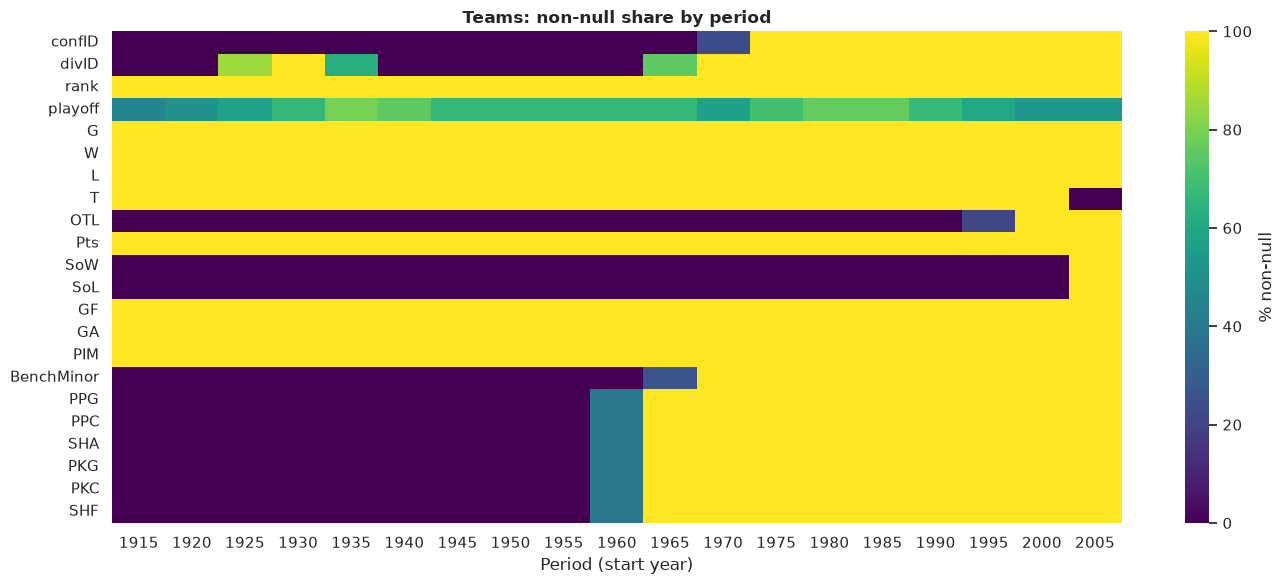

,first_year_90pct
G,1917.0
rank,1917.0
L,1917.0
W,1917.0
T,1917.0
PIM,1917.0
GF,1917.0
Pts,1917.0
GA,1917.0
divID,1926.0


In [6]:
def coverage_heatmap(df, title, exclude=(), step=5, figsize=(14, 6)):
    cols = [c for c in df.columns if c not in exclude and c != "year"]
    period = (df["year"] // step) * step
    cov = df[cols].notna().groupby(period).mean().T * 100
    plt.figure(figsize=figsize)
    sns.heatmap(cov, cmap="viridis", vmin=0, vmax=100, cbar_kws={"label": "% non-null"})
    plt.title(title, fontweight="bold")
    plt.xlabel("Period (start year)")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

def first_reliable_year(df, threshold=0.9, exclude=()):
    cols = [c for c in df.columns if c not in exclude and c != "year"]
    ok = df[cols].notna().groupby(df["year"]).mean().ge(threshold)
    return ok.idxmax().where(ok.any()).sort_values().rename("first_year_90pct")

teams_nhl = nhl(datasets["Teams"])
coverage_heatmap(teams_nhl, "Teams: non-null share by period", exclude=("lgID", "tmID", "franchID", "name"))
first_reliable_year(teams_nhl, exclude=("lgID", "tmID", "franchID", "name")).to_frame()

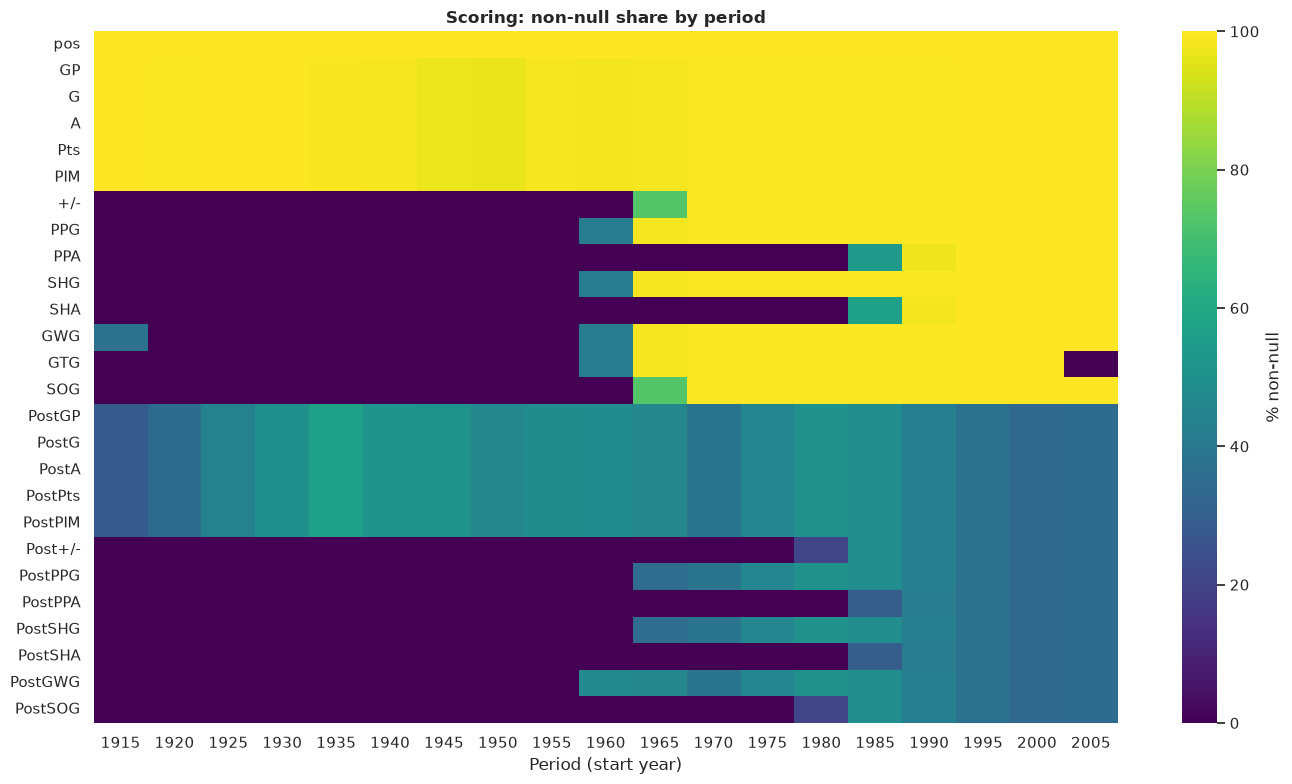

,first_year_90pct
GP,1917.0
G,1917.0
A,1917.0
Pts,1917.0
PIM,1917.0
GWG,1917.0
SHG,1963.0
PPG,1963.0
GTG,1963.0
+/-,1967.0


In [7]:
scoring_nhl_raw = nhl(datasets["Scoring"])
coverage_heatmap(scoring_nhl_raw, "Scoring: non-null share by period", exclude=("playerID", "tmID", "lgID", "stint"), figsize=(14, 8))
first_reliable_year(scoring_nhl_raw, exclude=("playerID", "tmID", "lgID", "stint", "pos")).to_frame()

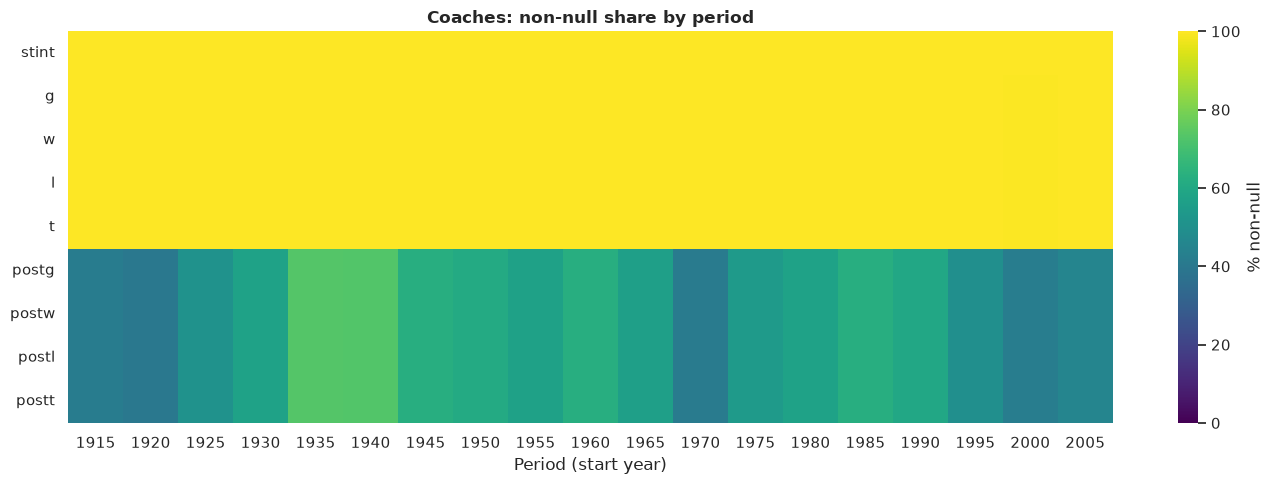

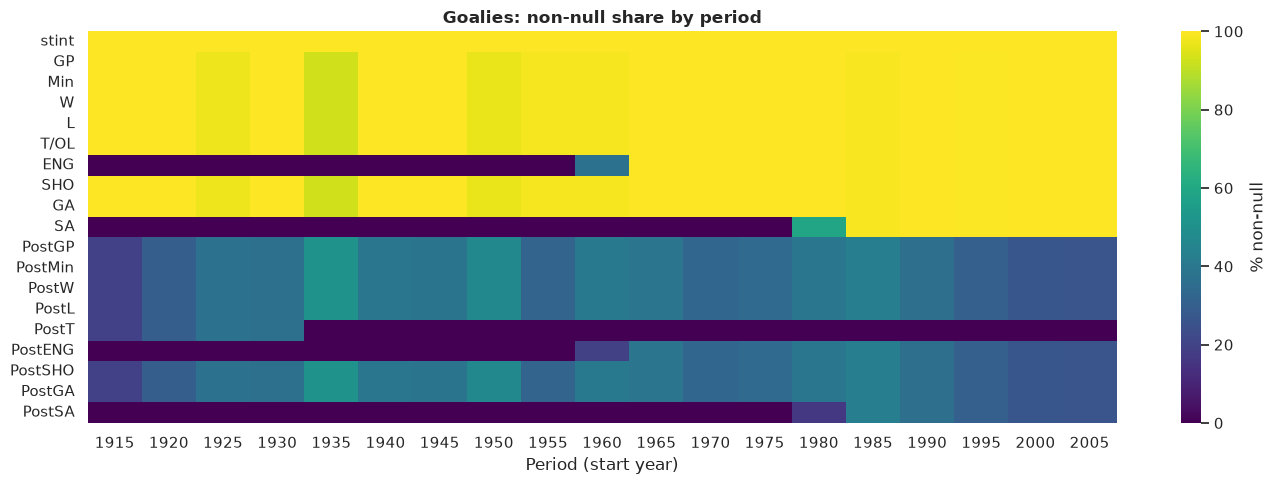

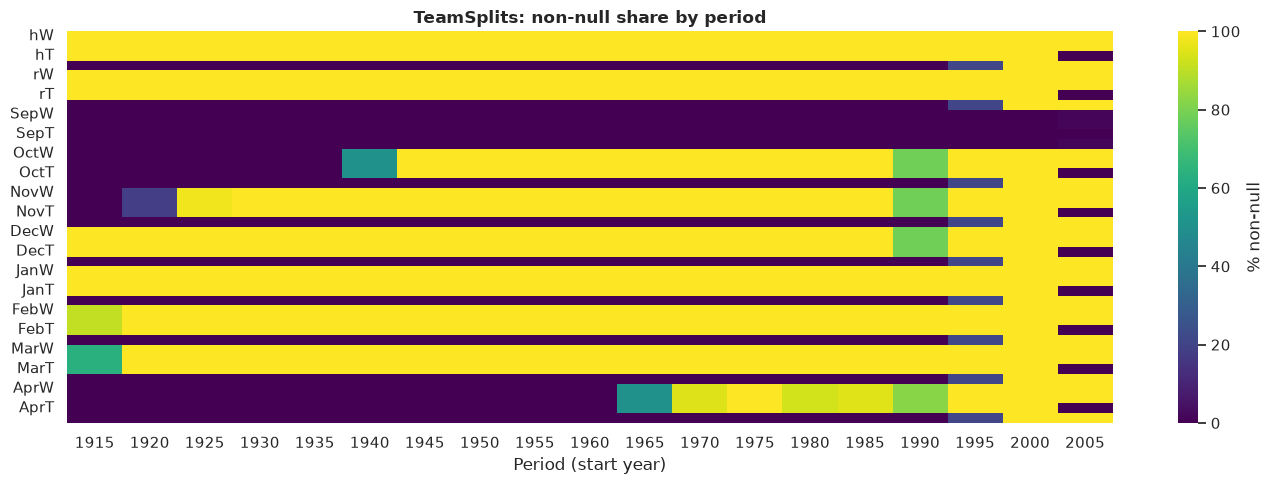

In [8]:
for name, ex in [("Coaches", ("coachID", "tmID", "lgID", "notes")), ("Goalies", ("playerID", "tmID", "lgID")), ("TeamSplits", ("tmID", "lgID"))]:
    coverage_heatmap(nhl(datasets[name]), f"{name}: non-null share by period", exclude=ex, figsize=(14, 5))

### Findings

- `Teams`: games, wins, losses, points, goals for/against, PIM and `rank` are complete for every year. Power-play and penalty-kill columns (`PPG`, `PPC`, `PKG`, `PKC`, `SHA`, `SHF`) start around 1963 and `BenchMinor` around 1968. Overtime losses are only filled from about 1999, shootout columns from 2005, and the tie column disappears after 2005.
- `Scoring`: `PIM` is complete in every period, which is what makes target (c) feasible. `+/-` and `SOG` start around 1967, `PPA` and `SHA` around 1988, and `GTG` disappears after 2005. The `Post*` columns are 30-60% filled because only players who reached the playoffs have them; this is not missing data in the usual sense.
- `Goalies`: minutes, goals against and wins are complete, but shots against (`SA`) is only filled from about 1983-85, so save percentage is only reliable from the mid-1980s.
- `Coaches`: `stint`, games, wins, losses and ties are complete across the whole history. The `post*` columns are only present for teams that played in the playoffs.
- `TeamSplits`: home and road wins are complete; monthly columns and the overtime-loss columns are only partially available.

Any window starting around 1990 has every column used below fully populated, which removes structural missingness as a concern.

### 2.3 How the league changed

If league-wide behaviour shifts over time, a model trained across all years learns a mix of different games. The grey dashed line marks the 1967 expansion and the red dotted line the first season after the 2004-05 lockout.

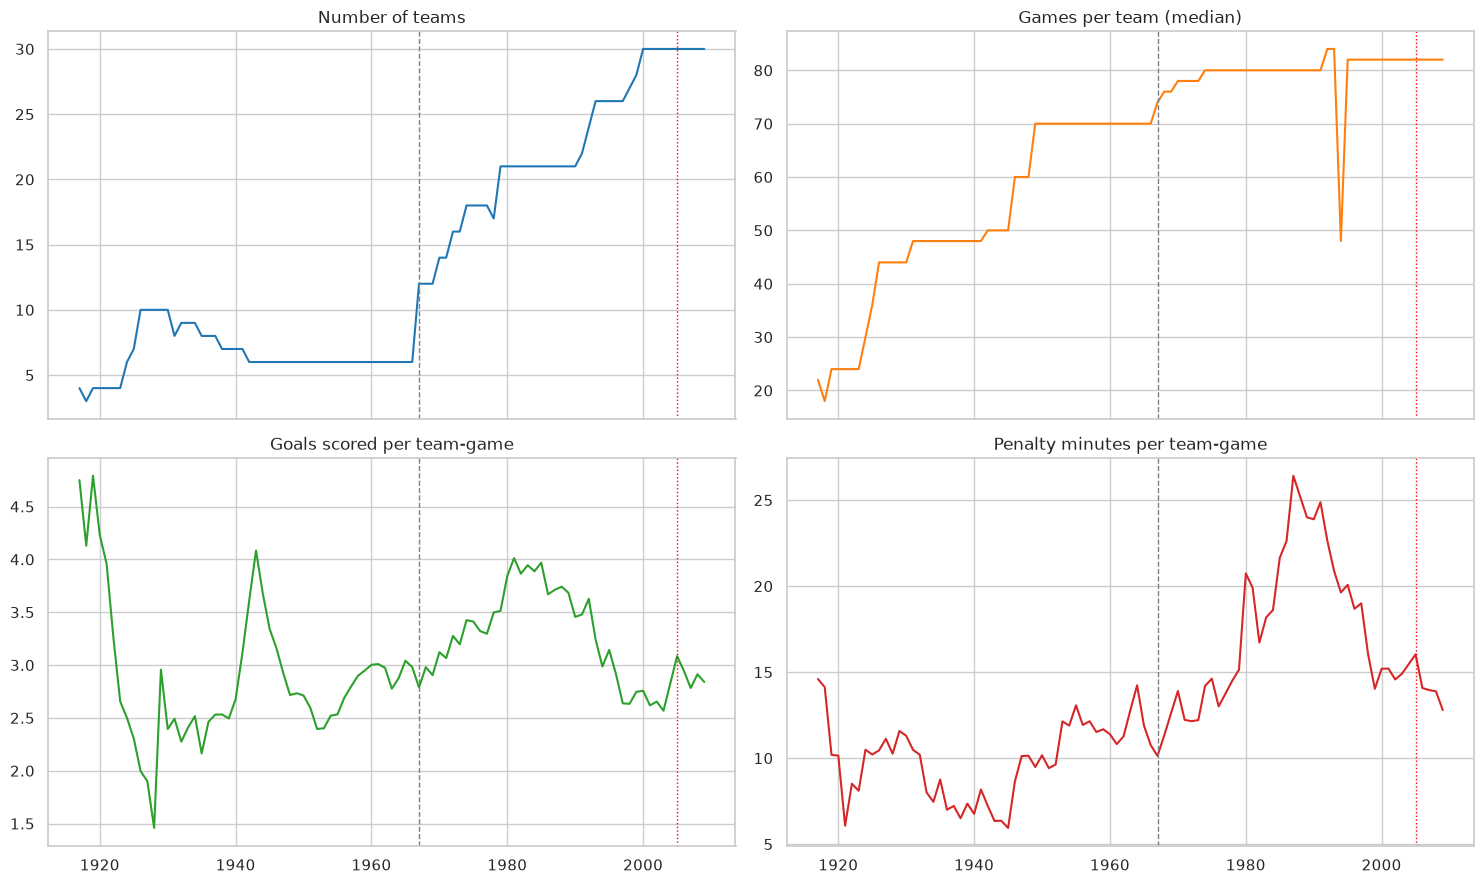

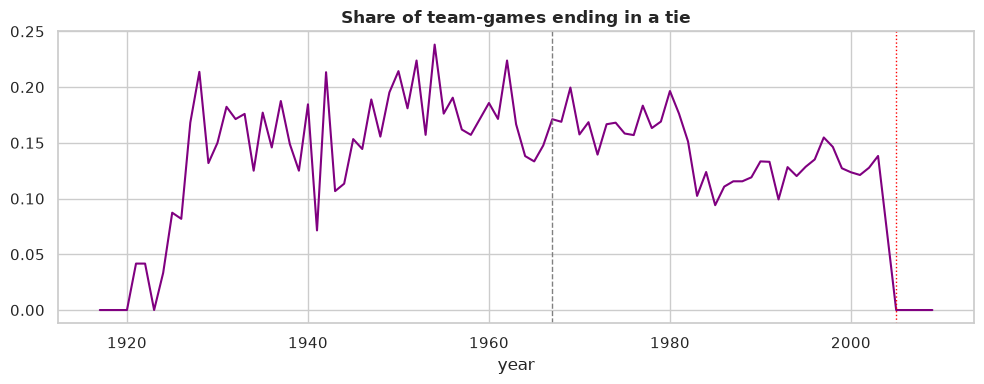

In [9]:
tt = to_num(nhl(datasets["Teams"]), ["G", "W", "L", "T", "OTL", "Pts", "GF", "GA", "PIM"])
season = tt.groupby("year").agg(n_teams=("tmID", "nunique"), games=("G", "median"), GF=("GF", "sum"), G=("G", "sum"),
                                T=("T", "sum"), PIM=("PIM", lambda s: s.sum(min_count=1)))
season["goals_per_team_game"] = season["GF"] / season["G"]
season["pim_per_team_game"] = season["PIM"] / season["G"]
season["tie_share"] = season["T"] / season["G"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True)
season["n_teams"].plot(ax=axes[0, 0], color="tab:blue")
axes[0, 0].set_title("Number of teams")
season["games"].plot(ax=axes[0, 1], color="tab:orange")
axes[0, 1].set_title("Games per team (median)")
season["goals_per_team_game"].plot(ax=axes[1, 0], color="tab:green")
axes[1, 0].set_title("Goals scored per team-game")
season["pim_per_team_game"].plot(ax=axes[1, 1], color="tab:red")
axes[1, 1].set_title("Penalty minutes per team-game")
for ax in axes.ravel():
    mark_events(ax)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
season["tie_share"].plot(ax=ax, color="purple")
mark_events(ax)
ax.set_title("Share of team-games ending in a tie", fontweight="bold")
plt.tight_layout()
plt.show()

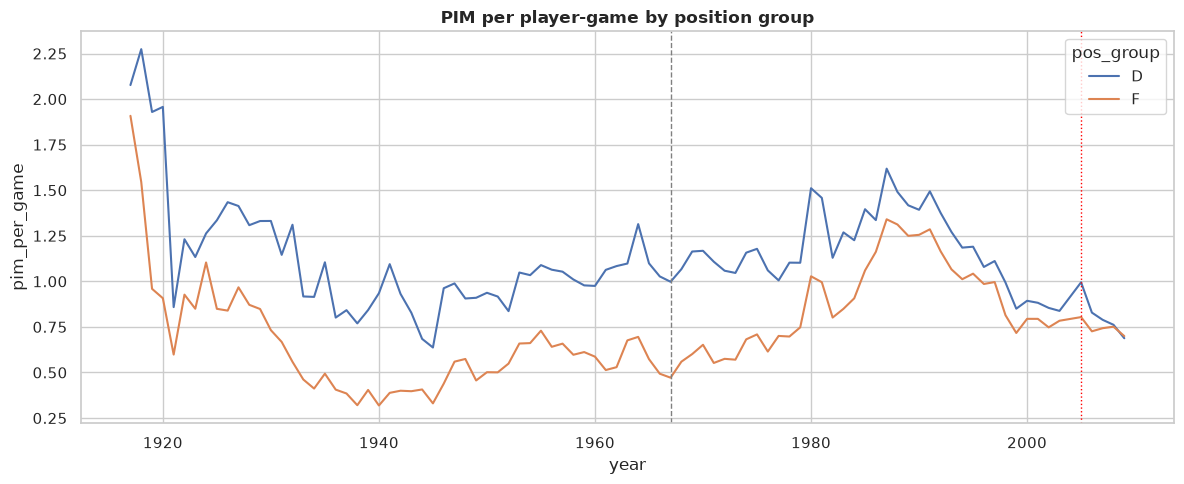

In [10]:
sp = to_num(scoring_nhl_raw.copy(), ["GP", "PIM"])
sp = sp[(sp["GP"] > 0) & sp["PIM"].notna()]
posstr = sp["pos"].astype(str)
sp["pos_group"] = np.where(posstr.str.startswith("G"), "G", np.where(posstr.str.startswith("D"), "D", "F"))
yr = sp[sp["pos_group"] != "G"].groupby(["year", "pos_group"]).agg(PIM=("PIM", "sum"), GP=("GP", "sum")).reset_index()
yr["pim_per_game"] = yr["PIM"] / yr["GP"]
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(data=yr, x="year", y="pim_per_game", hue="pos_group", ax=ax)
mark_events(ax)
ax.set_title("PIM per player-game by position group", fontweight="bold")
plt.tight_layout()
plt.show()

### Findings

- The league grew from 6 teams to 12 in 1967, 21 in 1979 and 30 in 2000. Ranks and raw counts are therefore not comparable across eras; the analysis uses rates and within-season percentiles.
- The number of games per team stabilised at 82 in 1995. The dip in 1994 (about 48 games) is the lockout-shortened season, and the 2004-05 season was not played at all, so a "previous season" can be two calendar years back.
- Scoring peaked above 3.8 goals per team-game in the 1980s, fell to roughly 2.6-2.8 between 1997 and 2003 and has stayed between 2.8 and 3.1 since the lockout.
- Penalty minutes per team-game peaked near 26 in 1987-88 and sit between 13 and 16 since about 1999. At player level, PIM per game for defensemen dropped from about 1.6 in 1987 to 0.7 in 2009, and the gap between defensemen and forwards has almost closed. Training on the 1980s would teach a penalty level that no longer exists.
- Ties end in 2005 with the introduction of shootouts, so points per game is the only comparable measure of team strength.

Window decision: 1995 onwards for the ranking and PIM tasks (82-game seasons, 26-30 teams, all columns complete) and 1990 onwards for coach changes, where events are rarer and extra seasons are worth having.

## 3. Data Preparation (DP)

### 3.1 Working tables

One row per team-season, with current-season columns used only as targets or reference and lagged columns (`_lag1`, `_lag2`, `_lag3`) for what is known before the season. Lags follow the franchise (`franchID`, falling back to `tmID`) through the previous seasons that exist, so the lockout appears as a two-year gap.

Definitions used throughout:

- `pts_pct` = points / (2 x games). It is the only strength measure comparable across eras.
- `rank_pct` = league-wide position by `pts_pct` within the season, rescaled to 0 (best) - 1 (worst). `Teams.rank` is the position within a division or conference, so it is not used as the target.
- `luck` = residual of `pts_pct` after regressing it on goal difference per game. It captures points won beyond what the goals scored and conceded would suggest.
- `made_playoffs` = the team has a non-empty `playoff` value.

In [11]:
t = to_num(nhl(datasets["Teams"]), ["G", "W", "L", "T", "OTL", "Pts", "GF", "GA", "PIM", "BenchMinor",
                                     "PPG", "PPC", "SHA", "PKG", "PKC", "SHF", "rank"])
t["entity"] = t["franchID"].where(t["franchID"].notna(), t["tmID"])
t = t.sort_values(["entity", "year"]).reset_index(drop=True)

t["pts_pct"] = t["Pts"] / (2 * t["G"])
t["win_pct"] = t["W"] / t["G"]
t["gf_pg"] = t["GF"] / t["G"]
t["ga_pg"] = t["GA"] / t["G"]
t["gd_pg"] = t["gf_pg"] - t["ga_pg"]
t["pim_pg"] = t["PIM"] / t["G"]
t["pp_pct"] = t["PPG"] / t["PPC"]
t["pk_pct"] = 1 - t["PKG"] / t["PKC"]

t["rank_league"] = t.groupby("year")["pts_pct"].rank(ascending=False, method="min")
t["n_teams"] = t.groupby("year")["tmID"].transform("count")
t["rank_pct"] = (t["rank_league"] - 1) / (t["n_teams"] - 1)

m = t["pts_pct"].notna() & t["gd_pg"].notna() & (t["year"] >= ERA_A)
slope, intercept = np.polyfit(t.loc[m, "gd_pg"], t.loc[m, "pts_pct"], 1)
t["luck"] = t["pts_pct"] - (intercept + slope * t["gd_pg"])

po = t["playoff"].astype(str).str.upper()
t["made_playoffs"] = (t["playoff"].notna() & (po != "N") & (po != "")).astype(float)
tp = to_num(nhl(datasets["TeamsPost"]), ["G", "W"]).groupby(["tmID", "year"], as_index=False).agg(post_g=("G", "sum"))
t = t.merge(tp, on=["tmID", "year"], how="left")
t["post_g"] = t["post_g"].fillna(0)
t["team_age"] = t["year"] - t.groupby("entity")["year"].transform("min")

ts = to_num(nhl(datasets["TeamSplits"]), ["hW", "hL", "hT", "hOTL", "rW", "rL", "rT", "rOTL"])
ts["home_games"] = ts[["hW", "hL", "hT", "hOTL"]].sum(axis=1, min_count=1)
ts["road_games"] = ts[["rW", "rL", "rT", "rOTL"]].sum(axis=1, min_count=1)
ts["home_adv"] = ts["hW"] / ts["home_games"] - ts["rW"] / ts["road_games"]
t = t.merge(ts[["tmID", "year", "home_adv"]], on=["tmID", "year"], how="left")

gl = to_num(nhl(datasets["Goalies"]), ["GP", "Min", "GA", "SA"])
gl = gl.groupby(["tmID", "year", "playerID"], as_index=False).agg(Min=("Min", "sum"), GA=("GA", "sum"), SA=("SA", "sum"))
gl = gl.sort_values(["tmID", "year", "Min"], ascending=[True, True, False]).drop_duplicates(["tmID", "year"])
gl["goalie_sv"] = np.where(gl["SA"] > 0, 1 - gl["GA"] / gl["SA"], np.nan)
t = t.merge(gl[["tmID", "year", "goalie_sv"]], on=["tmID", "year"], how="left")
t.shape

(1265, 45)

In [12]:
sc_all = to_num(nhl(datasets["Scoring"]), ["Pts"])
ps_team = sc_all.groupby(["tmID", "year", "playerID"], as_index=False)["Pts"].sum()
ps_team["pts_pos"] = ps_team["Pts"].clip(lower=0)
ps_team["rk"] = ps_team.groupby(["tmID", "year"])["pts_pos"].rank(method="first", ascending=False)
tot = ps_team.groupby(["tmID", "year"])["pts_pos"].sum().rename("tot")
top3 = ps_team[ps_team["rk"] <= 3].groupby(["tmID", "year"])["pts_pos"].sum().rename("top3")
roster = pd.concat([tot, top3], axis=1).reset_index()
roster["top3_pts_share"] = roster["top3"] / roster["tot"].replace(0, np.nan)

pairs = t[["tmID", "year"]].sort_values(["tmID", "year"]).copy()
pairs["prev_year"] = pairs.groupby("tmID")["year"].shift(1)
pairs = pairs.dropna(subset=["prev_year"])
pairs = pairs[pairs["year"] - pairs["prev_year"] <= MAX_GAP].copy()
pairs["prev_year"] = pairs["prev_year"].astype(int)
cont = pairs.merge(ps_team[["tmID", "year", "playerID", "pts_pos"]].rename(columns={"year": "prev_year", "pts_pos": "prev_pts"}), on=["tmID", "prev_year"])
cont = cont.merge(ps_team[["tmID", "year", "playerID"]].assign(stayed=1), on=["tmID", "year", "playerID"], how="left")
cont["stayed"] = cont["stayed"].fillna(0)
cont["stay_pts"] = cont["prev_pts"] * cont["stayed"]
ret = cont.groupby(["tmID", "year"]).agg(prev_pts_total=("prev_pts", "sum"), stay_pts=("stay_pts", "sum"), players=("stayed", "size"), stayed=("stayed", "sum")).reset_index()
ret["ret_pts_share"] = ret["stay_pts"] / ret["prev_pts_total"].replace(0, np.nan)
ret["ret_players_share"] = ret["stayed"] / ret["players"]

t = t.merge(roster[["tmID", "year", "top3_pts_share"]], on=["tmID", "year"], how="left")
t = t.merge(ret[["tmID", "year", "ret_pts_share", "ret_players_share"]], on=["tmID", "year"], how="left")
t[["year", "tmID", "top3_pts_share", "ret_pts_share", "ret_players_share"]].tail()

,year,tmID,top3_pts_share,ret_pts_share,ret_players_share
1260,2005,ATL,0.384203,0.584192,0.375000
1261,2006,ATL,0.402516,0.669344,0.527778
1262,2007,ATL,0.346225,0.617925,0.500000
1263,2008,ATL,0.358744,0.650092,0.625000
1264,2009,ATL,0.290172,0.807175,0.500000


In [13]:
c = to_num(nhl(datasets["Coaches"]), ["g", "w", "l", "t", "postg", "postw", "postl", "postt"])
n_c = c.groupby(["tmID", "year"])["coachID"].nunique().rename("n_coaches").reset_index()

main = (c.sort_values(["tmID", "year", "g"], ascending=[True, True, False])
          .drop_duplicates(["tmID", "year"])[["tmID", "year", "coachID", "g"]]
          .rename(columns={"coachID": "main_coach", "g": "main_coach_games"})
          .merge(n_c, on=["tmID", "year"]))
main = main.merge(t[["tmID", "year", "entity"]], on=["tmID", "year"], how="left")
main["entity"] = main["entity"].fillna(main["tmID"])
main["in_season_change"] = (main["n_coaches"] > 1).astype(float)
main = main.sort_values(["entity", "year"]).reset_index(drop=True)
g = main.groupby("entity")
main["prev_main_coach"] = g["main_coach"].shift(1)
main["prev_gap"] = main["year"] - g["year"].shift(1)
valid = main["prev_main_coach"].notna() & (main["prev_gap"] <= MAX_GAP)
main["new_main_coach"] = np.where(valid, (main["main_coach"] != main["prev_main_coach"]).astype(float), np.nan)
main["coach_change_any"] = np.where(valid, ((main["new_main_coach"] == 1) | (main["in_season_change"] == 1)).astype(float), np.nan)

def run_length(values):
    out, cnt, prev = [], 0, None
    for v in values:
        cnt = cnt + 1 if v == prev else 1
        out.append(cnt)
        prev = v
    return out

main["tenure"] = main.groupby("entity")["main_coach"].transform(lambda s: pd.Series(run_length(s.tolist()), index=s.index))
cy = c[["coachID", "year"]].drop_duplicates().sort_values(["coachID", "year"])
cy["career_seasons"] = cy.groupby("coachID").cumcount() + 1
main = main.merge(cy.rename(columns={"coachID": "main_coach"}), on=["main_coach", "year"], how="left")
main.head()

,tmID,year,main_coach,main_coach_games,n_coaches,entity,in_season_change,prev_main_coach,prev_gap,new_main_coach,coach_change_any,tenure,career_seasons
0,ANA,1993,wilsoro02c,84.0,1,ANA,0.0,NaN,NaN,NaN,NaN,1,1
1,ANA,1994,wilsoro02c,48.0,1,ANA,0.0,wilsoro02c,1.0,0.0,0.0,2,2
2,ANA,1995,wilsoro02c,82.0,1,ANA,0.0,wilsoro02c,1.0,0.0,0.0,3,3
3,ANA,1996,wilsoro02c,82.0,1,ANA,0.0,wilsoro02c,1.0,0.0,0.0,4,4
4,ANA,1997,pagepi01c,82.0,1,ANA,0.0,wilsoro02c,1.0,1.0,1.0,1,8


In [14]:
lag_cols = [c_ for c_ in ["pts_pct", "rank_pct", "gd_pg", "gf_pg", "ga_pg", "luck", "pim_pg", "pp_pct", "pk_pct", "made_playoffs",
                          "post_g", "home_adv", "goalie_sv", "top3_pts_share", "ret_pts_share", "ret_players_share"] if c_ in t.columns]
team = add_lags(t, "entity", lag_cols, lags=(1, 2, 3))
team["pts_pct_avg2"] = team[["pts_pct_lag1", "pts_pct_lag2"]].mean(axis=1)
team["pts_pct_avg3"] = team[["pts_pct_lag1", "pts_pct_lag2", "pts_pct_lag3"]].mean(axis=1)
team["trend_lag1"] = team["pts_pct_lag1"] - team["pts_pct_lag2"]
team = team.merge(main.drop(columns="entity"), on=["tmID", "year"], how="left")
team = team.sort_values(["entity", "year"]).reset_index(drop=True)

team_a = team[(team["year"] >= ERA_A) & (team["year_gap1"] <= MAX_GAP)].copy()
d = team_a.dropna(subset=["pts_pct", "pts_pct_avg2"])
b1, b0 = np.polyfit(d["pts_pct_avg2"], d["pts_pct"], 1)
team_a["resid"] = team_a["pts_pct"] - (b0 + b1 * team_a["pts_pct_avg2"])
print("team-seasons:", len(team), "| ranking window:", len(team_a))

team-seasons: 1265 | ranking window: 399


### 3.2 Candidate target and feature analysis: final ranking

Questions:

1. Is the provided `rank` usable as the target?
2. How much of a team's position carries over from one season to the next, and how many seasons of history help?
3. Which earlier-season variables add information beyond what the team's recent results already tell us?
4. Are the answers stable across eras?

The reference to beat is the naive prediction "same position as last season".

In [15]:
chk = team_a.groupby("year").agg(max_rank_column=("rank", "max"), n_teams=("n_teams", "first"), n_divisions=("divID", "nunique"))
display(chk.tail(8))
print("Mean within-season Spearman between Teams.rank and the league-wide rank:",
      round(team_a.groupby("year").apply(lambda d_: spearman(d_["rank"], d_["rank_league"])).mean(), 3))

,max_rank_column,n_teams,n_divisions
year,,,
2001,5,30,6
2002,5,30,6
2003,5,30,6
2005,5,30,6
2006,5,30,6
2007,5,30,6
2008,5,30,6
2009,5,30,6


Mean within-season Spearman between Teams.rank and the league-wide rank: 0.87


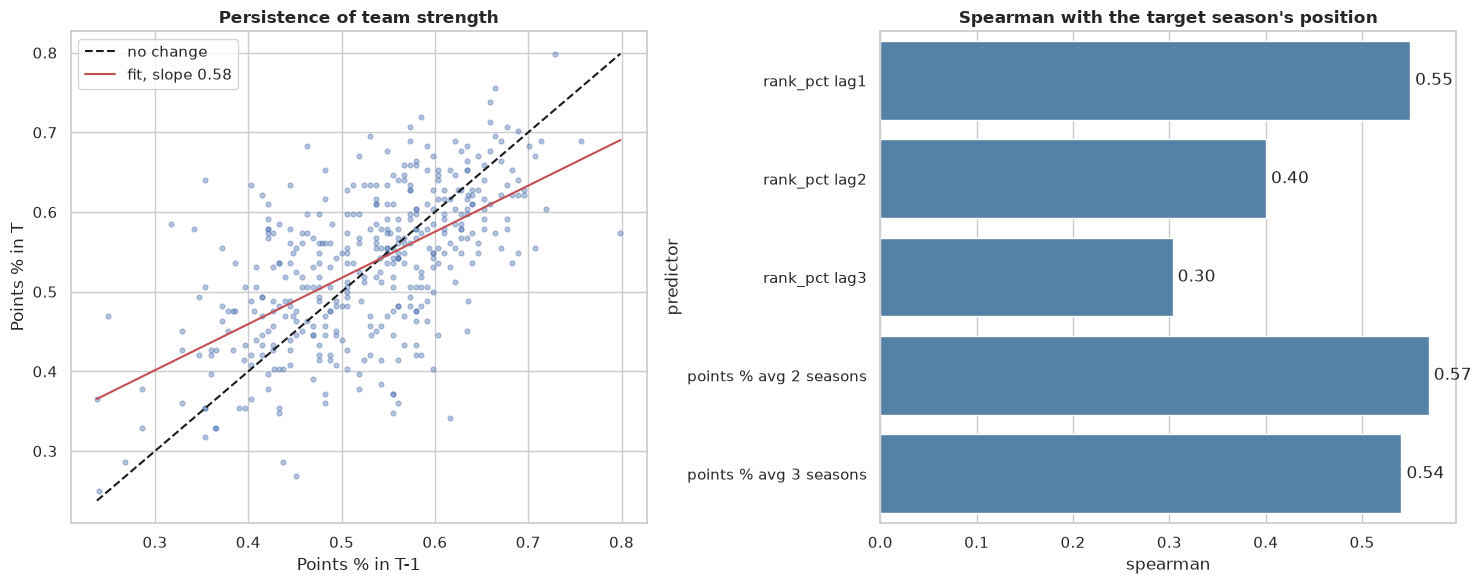

points % in T = 0.228 + 0.579 x points % in T-1   (r = 0.60)


In [16]:
d = team_a.dropna(subset=["pts_pct", "pts_pct_lag1"])
s1, s0 = np.polyfit(d["pts_pct_lag1"], d["pts_pct"], 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(d["pts_pct_lag1"], d["pts_pct"], s=12, alpha=0.4)
xs = np.linspace(d["pts_pct_lag1"].min(), d["pts_pct_lag1"].max(), 50)
axes[0].plot(xs, xs, "k--", label="no change")
axes[0].plot(xs, s0 + s1 * xs, "r", label=f"fit, slope {s1:.2f}")
axes[0].set_xlabel("Points % in T-1")
axes[0].set_ylabel("Points % in T")
axes[0].legend()
axes[0].set_title("Persistence of team strength", fontweight="bold")

rows = [{"predictor": f"rank_pct lag{k}", "spearman": spearman(team_a["rank_pct"], team_a[f"rank_pct_lag{k}"])} for k in (1, 2, 3)]
rows += [{"predictor": "points % avg 2 seasons", "spearman": spearman(team_a["pts_pct"], team_a["pts_pct_avg2"])},
         {"predictor": "points % avg 3 seasons", "spearman": spearman(team_a["pts_pct"], team_a["pts_pct_avg3"])}]
sns.barplot(data=pd.DataFrame(rows), y="predictor", x="spearman", ax=axes[1], color="steelblue")
for p in axes[1].patches:
    axes[1].text(p.get_width(), p.get_y() + p.get_height() / 2, f" {p.get_width():.2f}", va="center")
axes[1].set_title("Spearman with the target season's position", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"points % in T = {s0:.3f} + {s1:.3f} x points % in T-1   (r = {d['pts_pct'].corr(d['pts_pct_lag1']):.2f})")

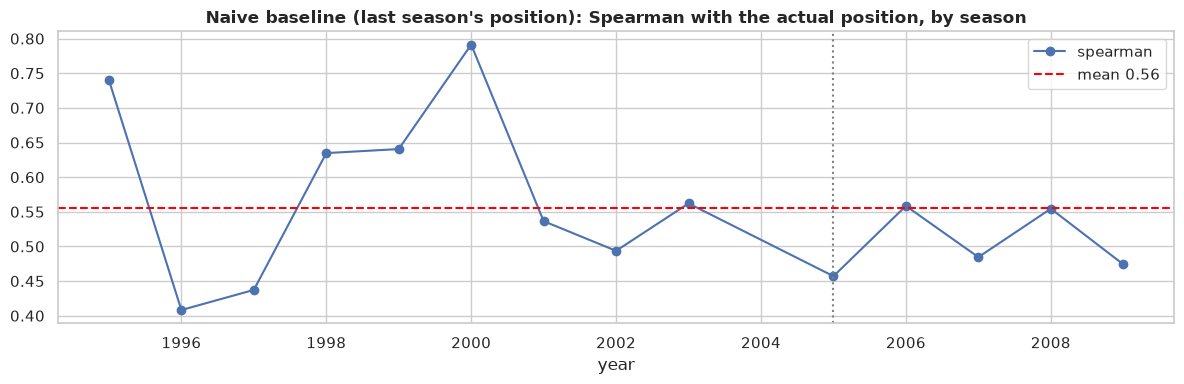

,period,team_seasons,spearman_vs_last_season,slope
0,1980-1994,324,0.579,0.601
1,1995-2004,249,0.576,0.606
2,2005-2009,150,0.507,0.472


Persistence slope by period: 1980-1994: 0.601; 1995-2004: 0.606; 2005-2009: 0.472. Spearman with last season: 1980-1994: 0.579; 1995-2004: 0.576; 2005-2009: 0.507.

In [17]:
base = team_a.groupby("year").apply(lambda d_: spearman(d_["rank_pct"], d_["rank_pct_lag1"])).rename("spearman")
fig, ax = plt.subplots(figsize=(12, 4))
base.plot(ax=ax, marker="o")
ax.axhline(base.mean(), color="red", ls="--", label=f"mean {base.mean():.2f}")
ax.axvline(FIRST_POST_LOCKOUT, color="grey", ls=":")
ax.legend()
ax.set_title("Naive baseline (last season's position): Spearman with the actual position, by season", fontweight="bold")
plt.tight_layout()
plt.show()

windows = {"1980-1994": (1980, 1994), "1995-2004": (1995, 2004), "2005-2009": (2005, 2009)}
rows = []
for label, (lo, hi) in windows.items():
    w = team[(team["year"] >= lo) & (team["year"] <= hi) & (team["year_gap1"] <= MAX_GAP)].dropna(subset=["pts_pct", "pts_pct_lag1"])
    sl = np.polyfit(w["pts_pct_lag1"], w["pts_pct"], 1)[0]
    rows.append({"period": label, "team_seasons": len(w), "spearman_vs_last_season": round(spearman(w["rank_pct"], w["rank_pct_lag1"]), 3), "slope": round(sl, 3)})
res_w = pd.DataFrame(rows)
display(res_w)
display(Markdown("Persistence slope by period: " + "; ".join(f"{r.period}: {r.slope}" for r in res_w.itertuples()) + ". Spearman with last season: " + "; ".join(f"{r.period}: {r.spearman_vs_last_season}" for r in res_w.itertuples()) + "."))

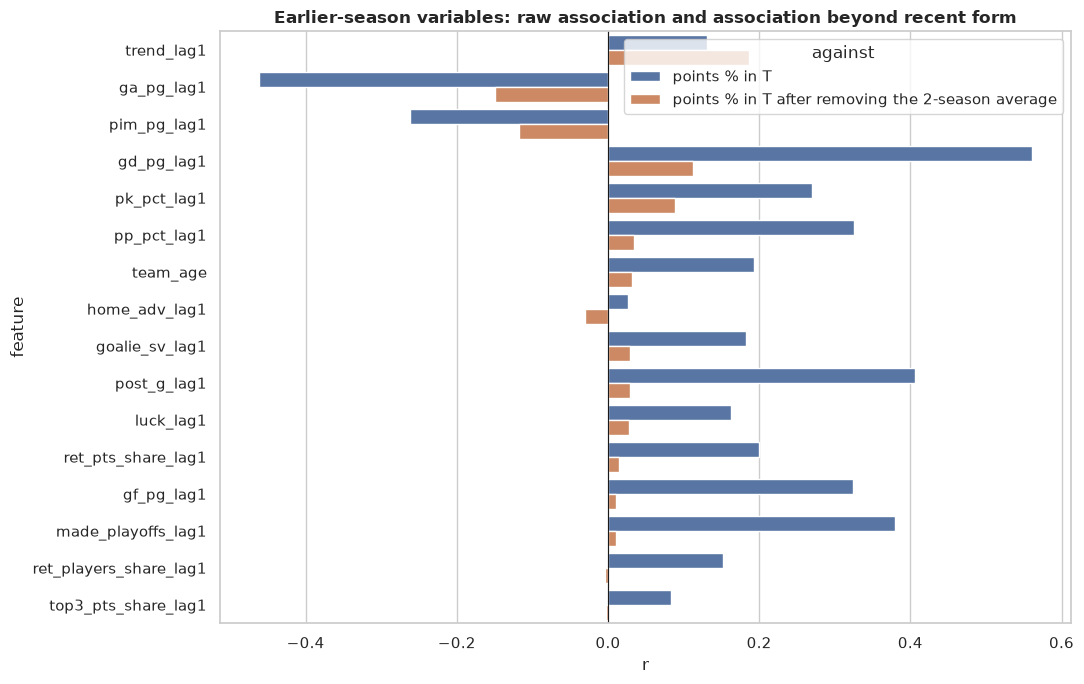

,n,with_points_pct,beyond_recent_form,p_value,decision
feature,,,,,
trend_lag1,395,0.131,0.186,0.0002,keep
ga_pg_lag1,399,-0.462,-0.150,0.0027,keep
pim_pg_lag1,399,-0.262,-0.118,0.0182,keep
gd_pg_lag1,399,0.561,0.112,0.0251,keep
pk_pct_lag1,399,0.270,0.088,0.0787,drop
pp_pct_lag1,399,0.326,0.035,0.4878,drop
team_age,399,0.193,0.032,0.5298,drop
home_adv_lag1,399,0.026,-0.030,0.5482,drop
goalie_sv_lag1,399,0.182,0.029,0.5605,drop


In [18]:
feats_a = [f for f in ["trend_lag1", "gd_pg_lag1", "gf_pg_lag1", "ga_pg_lag1", "luck_lag1", "pim_pg_lag1", "pp_pct_lag1",
                       "pk_pct_lag1", "made_playoffs_lag1", "post_g_lag1", "home_adv_lag1", "goalie_sv_lag1", "team_age",
                       "top3_pts_share_lag1", "ret_pts_share_lag1", "ret_players_share_lag1"] if f in team_a.columns]
level = spearman_table(team_a, feats_a, "pts_pct").set_index("feature")["spearman"].rename("with_points_pct")
partial = spearman_table(team_a, feats_a, "resid")
cmp_a = partial.set_index("feature").join(level)
plot_a = cmp_a.reset_index().melt(id_vars="feature", value_vars=["with_points_pct", "spearman"], var_name="against", value_name="r")
plot_a["against"] = plot_a["against"].map({"with_points_pct": "points % in T", "spearman": "points % in T after removing the 2-season average"})
plt.figure(figsize=(11, 7))
sns.barplot(data=plot_a, y="feature", x="r", hue="against")
plt.axvline(0, color="k", lw=0.8)
plt.title("Earlier-season variables: raw association and association beyond recent form", fontweight="bold")
plt.tight_layout()
plt.show()
cmp_a[["n", "with_points_pct", "spearman", "p_value", "decision"]].rename(columns={"spearman": "beyond_recent_form"})

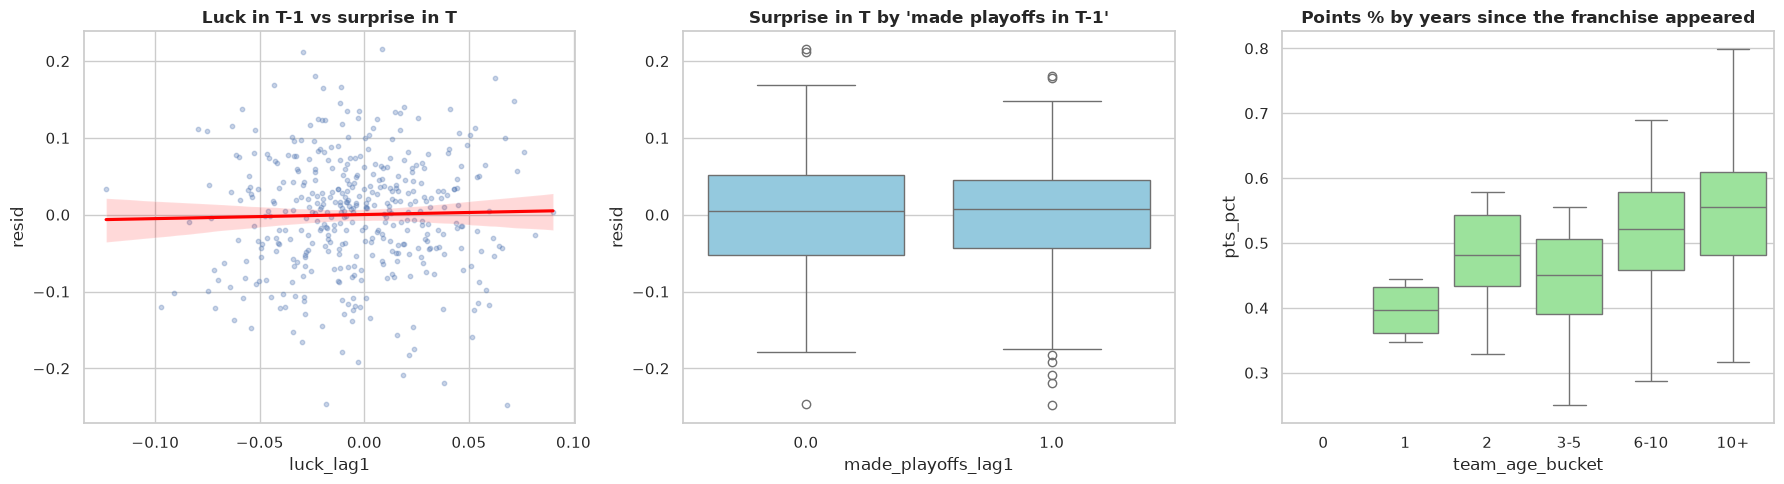

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
dd = team_a.dropna(subset=["luck_lag1", "resid"])
sns.regplot(data=dd, x="luck_lag1", y="resid", scatter_kws={"s": 10, "alpha": 0.3}, line_kws={"color": "red"}, ax=axes[0])
axes[0].set_title("Luck in T-1 vs surprise in T", fontweight="bold")
sns.boxplot(data=team_a.dropna(subset=["made_playoffs_lag1", "resid"]), x="made_playoffs_lag1", y="resid", ax=axes[1], color="skyblue")
axes[1].set_title("Surprise in T by 'made playoffs in T-1'", fontweight="bold")
team_a["team_age_bucket"] = pd.cut(team_a["team_age"], [-1, 0, 1, 2, 5, 10, 100], labels=["0", "1", "2", "3-5", "6-10", "10+"])
sns.boxplot(data=team_a, x="team_age_bucket", y="pts_pct", ax=axes[2], color="lightgreen")
axes[2].set_title("Points % by years since the franchise appeared", fontweight="bold")
plt.tight_layout()
plt.show()

,variable,known_before_season,spearman_with_surprise
0,ret_pts_share,False,0.156
1,ret_players_share,False,0.015
2,ret_pts_share_lag1,True,0.014
3,ret_players_share_lag1,True,-0.004
4,top3_pts_share_lag1,True,-0.003


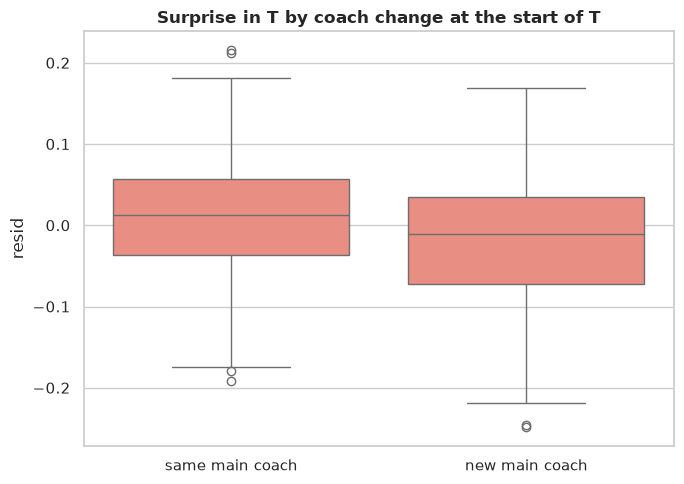

,count,mean,median
new_main_coach,,,
0.0,256,0.011,0.012
1.0,143,-0.019,-0.011


Mean surprise in points % with a new main coach: -0.019 (n=143); with the same coach: +0.011 (n=256).

In [20]:
extra = team_a.copy()
rows = []
for col in ["ret_pts_share", "ret_players_share", "ret_pts_share_lag1", "ret_players_share_lag1", "top3_pts_share_lag1"]:
    if col in extra.columns:
        rows.append({"variable": col, "known_before_season": col.endswith("_lag1"), "spearman_with_surprise": round(spearman(extra[col], extra["resid"]), 3)})
display(pd.DataFrame(rows))

dd = extra.dropna(subset=["new_main_coach", "resid"])
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=dd, x="new_main_coach", y="resid", color="salmon", ax=ax)
ax.set_xticklabels(["same main coach", "new main coach"])
ax.set_xlabel("")
ax.set_title("Surprise in T by coach change at the start of T", fontweight="bold")
plt.tight_layout()
plt.show()
cs = dd.groupby("new_main_coach")["resid"].agg(["count", "mean", "median"]).round(3)
display(cs)
display(Markdown(f"Mean surprise in points % with a new main coach: {cs.loc[1.0, 'mean']:+.3f} (n={int(cs.loc[1.0, 'count'])}); with the same coach: {cs.loc[0.0, 'mean']:+.3f} (n={int(cs.loc[0.0, 'count'])})."))

In [21]:
keep_a = cmp_a[cmp_a["decision"] == "keep"].index.tolist()
drop_a = cmp_a[cmp_a["decision"] == "drop"].index.tolist()
display(Markdown(
    f"**Beyond recent form (criterion: |Spearman| >= 0.10 and p < 0.05):**\n\n"
    f"- Informative: {', '.join(keep_a) if keep_a else 'none'}\n"
    f"- Not informative: {', '.join(drop_a) if drop_a else 'none'}"))

**Beyond recent form (criterion: |Spearman| >= 0.10 and p < 0.05):**

- Informative: trend_lag1, ga_pg_lag1, pim_pg_lag1, gd_pg_lag1
- Not informative: pk_pct_lag1, pp_pct_lag1, team_age, home_adv_lag1, goalie_sv_lag1, post_g_lag1, luck_lag1, ret_pts_share_lag1, gf_pg_lag1, made_playoffs_lag1, ret_players_share_lag1, top3_pts_share_lag1

### Findings

- `Teams.rank` cannot be the target. It never exceeds 5 while there are 30 teams, because it is the position inside a division. Its within-season Spearman with the league-wide ranking from points % is 0.87, so the league-wide ranking is used instead.
- Team strength carries over only partly: the fitted slope between points % in consecutive seasons is 0.58 (r = 0.60), so roughly 40% of a team's distance from the league average disappears each year.
- The naive baseline "same position as last season" reaches a mean Spearman of 0.56. It ranges from 0.41 (1996) to 0.79 (2000) and stays between 0.46 and 0.56 since 2005. This is the score a model has to beat.
- Two seasons of history work best: Spearman 0.57 for the two-season average of points %, against 0.55 for last season alone. A third season brings no gain (0.54), and the position two and three seasons back is much weaker on its own (0.40 and 0.30).
- Raw associations with the target are strongest for last season's points % (0.59) and goal difference per game (0.56), followed by goals against (-0.46), playoff games (0.41), making the playoffs (0.38), power-play efficiency (0.33) and goals for (0.32). Most of this overlaps with last season's points, so the table of section 5 measures what each variable adds after removing the two-season average of points %.
- Beyond recent form, only four variables keep a meaningful association: the trend between last season and the one before (+0.19), goals against per game (-0.15), team penalty minutes per game (-0.12) and goal difference per game (+0.11). The positive trend says the most recent season should weigh more than the older one. Goals against and goal difference say that how the points were obtained matters: teams that conceded more than their points suggest tend to fall, teams with a better goal difference tend to rise. Penalty-heavy teams underperform.
- Everything else collapses once recent form is controlled for: power play (0.33 to 0.04), penalty kill (0.27 to 0.09, p = 0.08), playoff games (0.41 to 0.03), making the playoffs (0.38 to 0.01), goals for (0.32 to 0.01), goalie save percentage (0.18 to 0.03), luck (0.16 to 0.03), franchise age (0.19 to 0.03), home advantage (0.03 to -0.03). They describe the same strength that points % already captures and add nothing for the ranking model.
- Roster stability known before the season has no value: retention in T-1 (0.01) and the share of points scored by the top three scorers (0.00) are unrelated to the surprise. Retention measured on the 2010 roster correlates 0.16 with it, so knowing the final roster would help somewhat, but that information is not available the day before the first game.
- A new main coach at the start of the season goes with a slightly worse outcome (mean surprise -0.019, n = 143, against +0.011, n = 256). The difference is about three points of points %, too small and too late (the coach is not known in advance) to use.
- Persistence is stable between 1980-1994 (slope 0.60, Spearman 0.58) and 1995-2004 (0.61, 0.58) but weaker after the lockout (0.47, 0.51). The league became more balanced after 2005, which makes the ranking harder to predict. The 1995 start is therefore chosen for structural reasons (82 games, 26-30 teams, complete variables), and recent seasons should carry more weight than older ones.


### 3.3 Candidate target and feature analysis: coach changes

The target is `in_season_change`: a team-season in which more than one coach appears in `Coaches`, meaning the coach changed between the first and the last game of the season. The file does not say who started the season, so the coach with most games is treated as the main coach where one is needed. Changes between seasons (a different main coach than the year before) are shown only to put the base rate in context.

Questions:

1. How common is the event, and does it change over time?
2. Is it related to last season's results, the coach's tenure and profile, or the history of the franchise?
3. Which variables separate seasons with a change from seasons without one?

Variables are scored with the area under the ROC curve (AUC) computed on one variable at a time, with a bootstrap 95% interval. A variable is kept when the interval excludes 0.5.

In [22]:
tb = team.copy()
tb["tenure_lag1"] = tb.groupby("entity")["tenure"].shift(1)
tb["career_seasons_lag1"] = tb.groupby("entity")["career_seasons"].shift(1)
tb["in_season_change_lag1"] = tb.groupby("entity")["in_season_change"].shift(1)
tb["main_coach_lag1"] = tb.groupby("entity")["main_coach"].shift(1)

mst = datasets["Master"]
cb_age = mst[["coachID", "birthYear"]].dropna().drop_duplicates("coachID").rename(columns={"coachID": "main_coach_lag1"})
tb = tb.merge(cb_age, on="main_coach_lag1", how="left")
tb["coach_age"] = tb["year"] - tb["birthYear"]

ac = datasets["AwardsCoaches"]
aw_years = {k: v.values for k, v in ac.groupby("coachID")["year"]}
ja_years = {k: v.values for k, v in ac[ac["award"].astype(str).str.contains("Jack Adams", case=False)].groupby("coachID")["year"]}

def awards_before(d_, coach, year):
    arr = d_.get(coach)
    return 0 if (arr is None or pd.isna(coach)) else int((arr < year).sum())

tb["coach_awards_prior"] = [awards_before(aw_years, cc, y) for cc, y in zip(tb["main_coach_lag1"], tb["year"])]
tb["coach_jack_adams_prior"] = [awards_before(ja_years, cc, y) for cc, y in zip(tb["main_coach_lag1"], tb["year"])]

tb = tb.sort_values(["entity", "year"])
tb["franchise_change_rate_hist"] = tb.groupby("entity")["in_season_change"].transform(lambda s: s.shift(1).expanding().mean())

TARGET_B = "in_season_change"
cb = tb[(tb["year"] >= ERA_B) & tb[TARGET_B].notna() & (tb["year_gap1"] <= MAX_GAP)].copy()
cb[TARGET_B] = cb[TARGET_B].astype(int)
print("team-seasons:", len(cb), "| seasons with a change:", int(cb[TARGET_B].sum()), "| base rate:", round(cb[TARGET_B].mean(), 3))

team-seasons: 513 | seasons with a change: 91 | base rate: 0.177


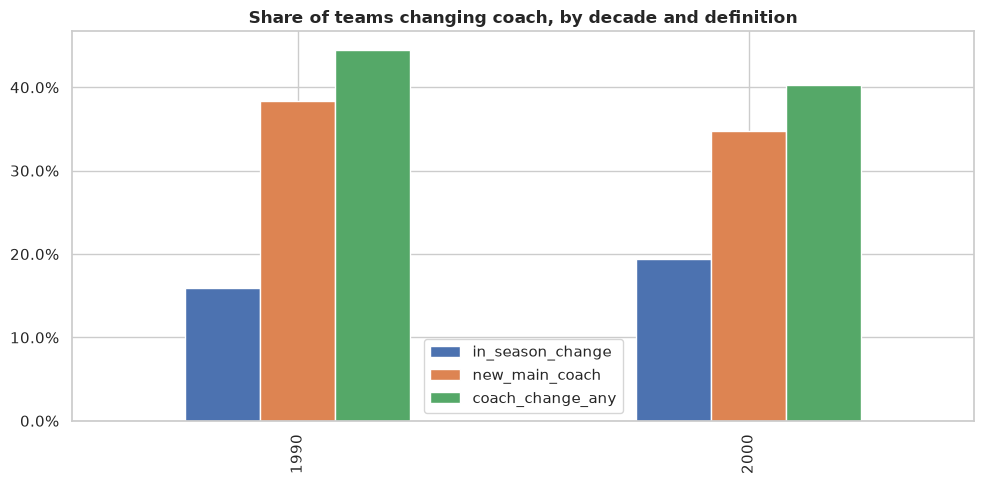

,in_season_change,new_main_coach,coach_change_any,team_seasons
decade,,,,
1990,0.159,0.384,0.445,245
2000,0.194,0.347,0.403,268


In [23]:
cb["decade"] = (cb["year"] // 10) * 10
rates = cb.groupby("decade")[["in_season_change", "new_main_coach", "coach_change_any"]].mean()
counts = cb.groupby("decade").size().rename("team_seasons")
fig, ax = plt.subplots(figsize=(10, 5))
rates.plot(kind="bar", ax=ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("")
ax.set_title("Share of teams changing coach, by decade and definition", fontweight="bold")
plt.tight_layout()
plt.show()
rates.join(counts).round(3)

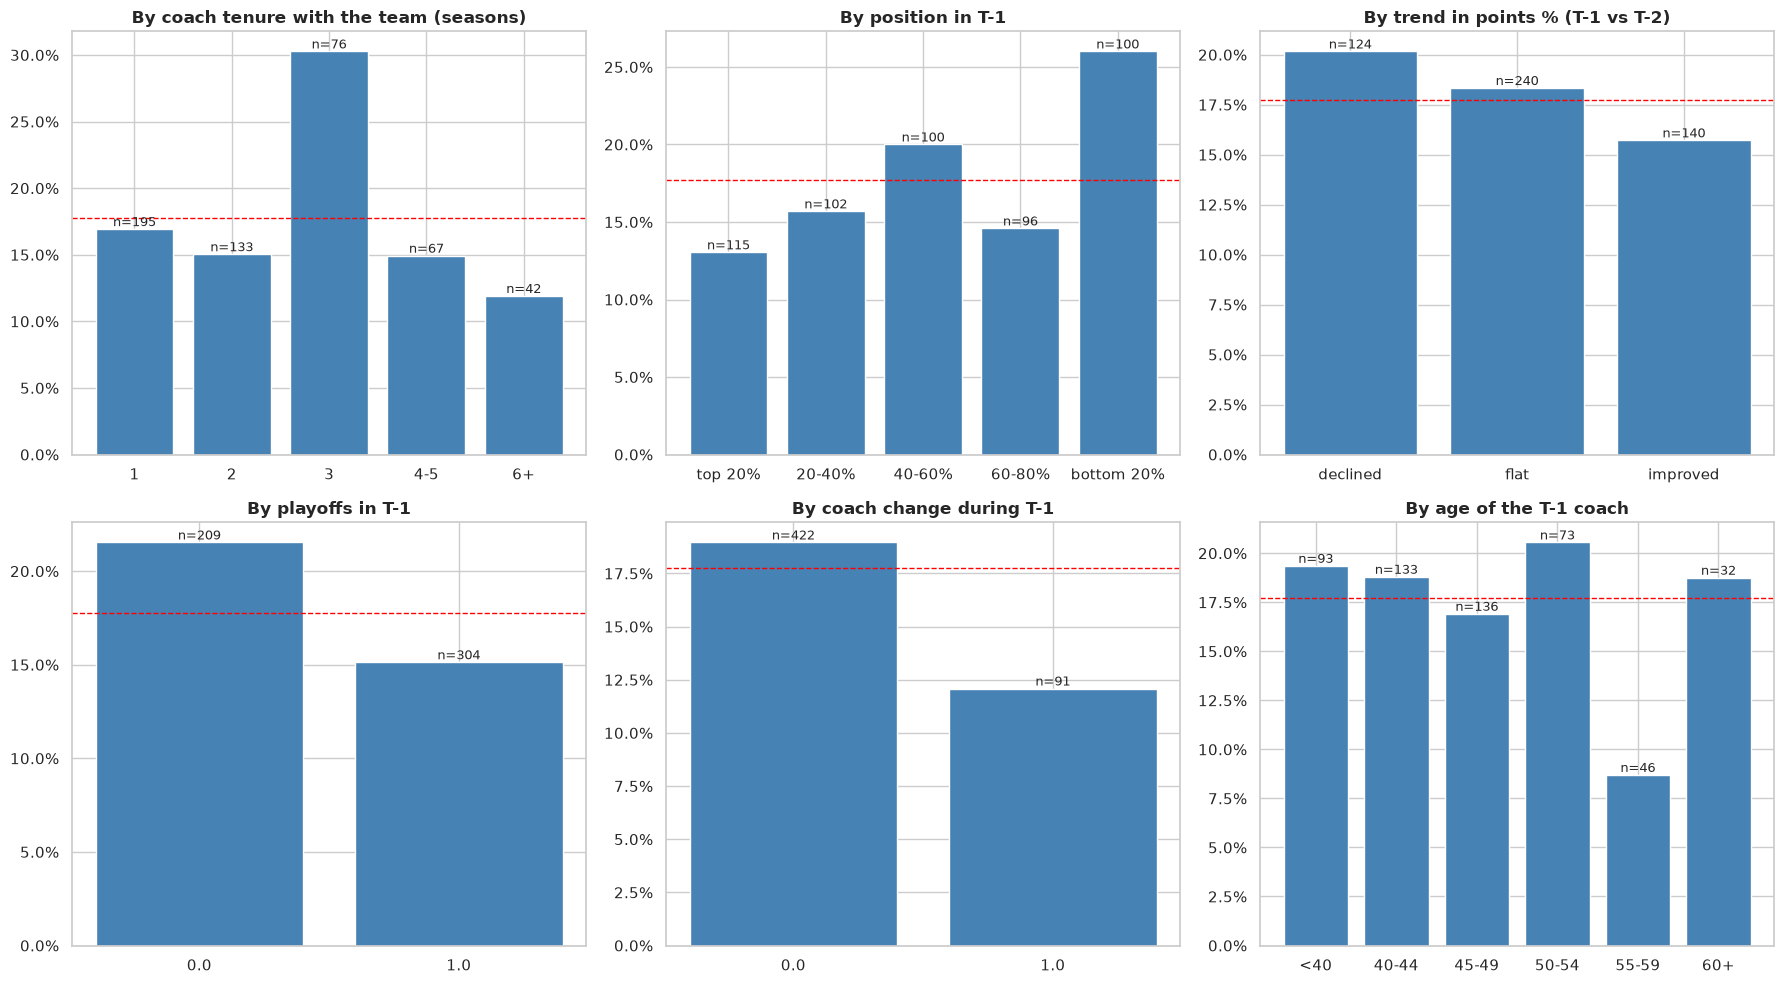

In [24]:
def rate_plot(ax, df, by, title):
    r = df.groupby(by, observed=True)[TARGET_B].agg(["mean", "count"]).reset_index()
    ax.bar(r[by].astype(str), r["mean"], color="steelblue")
    for i, (m_, n_) in enumerate(zip(r["mean"], r["count"])):
        ax.text(i, m_, f"n={n_}", ha="center", va="bottom", fontsize=9)
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("")
    ax.axhline(cb[TARGET_B].mean(), color="red", ls="--", lw=1)

cb["tenure_bucket"] = pd.cut(cb["tenure_lag1"], [0, 1, 2, 3, 5, 100], labels=["1", "2", "3", "4-5", "6+"])
cb["rank_lag1_bucket"] = pd.cut(cb["rank_pct_lag1"], [-0.01, 0.2, 0.4, 0.6, 0.8, 1.0], labels=["top 20%", "20-40%", "40-60%", "60-80%", "bottom 20%"])
cb["trend_bucket"] = pd.cut(cb["trend_lag1"], [-1, -0.05, 0.05, 1], labels=["declined", "flat", "improved"])
cb["age_bucket"] = pd.cut(cb["coach_age"], [0, 40, 45, 50, 55, 60, 100], labels=["<40", "40-44", "45-49", "50-54", "55-59", "60+"])

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
rate_plot(axes[0, 0], cb.dropna(subset=["tenure_bucket"]), "tenure_bucket", "By coach tenure with the team (seasons)")
rate_plot(axes[0, 1], cb.dropna(subset=["rank_lag1_bucket"]), "rank_lag1_bucket", "By position in T-1")
rate_plot(axes[0, 2], cb.dropna(subset=["trend_bucket"]), "trend_bucket", "By trend in points % (T-1 vs T-2)")
rate_plot(axes[1, 0], cb.dropna(subset=["made_playoffs_lag1"]), "made_playoffs_lag1", "By playoffs in T-1")
rate_plot(axes[1, 1], cb.dropna(subset=["in_season_change_lag1"]), "in_season_change_lag1", "By coach change during T-1")
rate_plot(axes[1, 2], cb.dropna(subset=["age_bucket"]), "age_bucket", "By age of the T-1 coach")
plt.tight_layout()
plt.show()

- tenure: highest 3 (30%, n=76), lowest 6+ (12%, n=42); overall 18%
- position in T-1: highest bottom 20% (26%, n=100), lowest top 20% (13%, n=115); overall 18%
- trend in points %: highest declined (20%, n=124), lowest improved (16%, n=140); overall 18%
- playoffs in T-1: highest 0.0 (22%, n=209), lowest 1.0 (15%, n=304); overall 18%
- change during T-1: highest 0.0 (19%, n=422), lowest 1.0 (12%, n=91); overall 18%
- coach age: highest 50-54 (21%, n=73), lowest 55-59 (9%, n=46); overall 18%

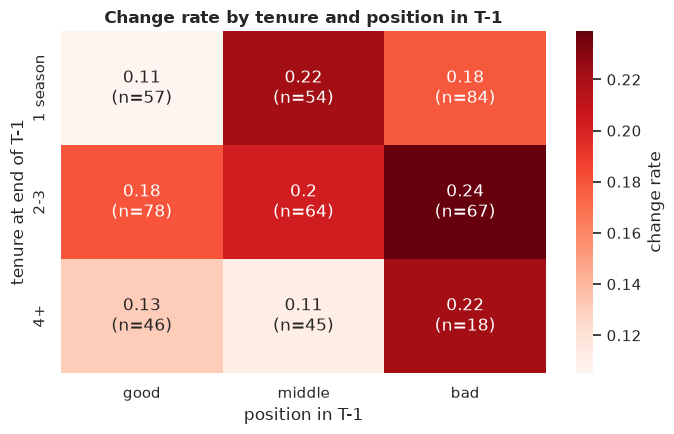

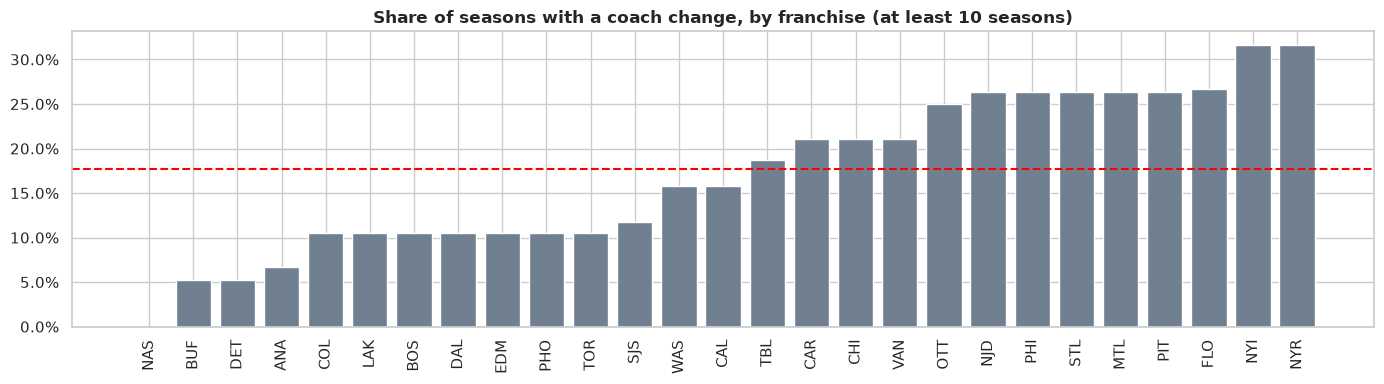

In [25]:
lines = []
for col, label in [("tenure_bucket", "tenure"), ("rank_lag1_bucket", "position in T-1"), ("trend_bucket", "trend in points %"),
                   ("made_playoffs_lag1", "playoffs in T-1"), ("in_season_change_lag1", "change during T-1"), ("age_bucket", "coach age")]:
    r = cb.groupby(col, observed=True)[TARGET_B].agg(["mean", "count"])
    r = r[r["count"] >= 20]
    if len(r) > 1:
        hi, lo = r["mean"].idxmax(), r["mean"].idxmin()
        lines.append(f"- {label}: highest {hi} ({r.loc[hi, 'mean']:.0%}, n={int(r.loc[hi, 'count'])}), lowest {lo} ({r.loc[lo, 'mean']:.0%}, n={int(r.loc[lo, 'count'])}); overall {cb[TARGET_B].mean():.0%}")
display(Markdown("\n".join(lines)))

cb["tenure_3"] = pd.cut(cb["tenure_lag1"], [0, 1, 3, 100], labels=["1 season", "2-3", "4+"])
cb["rank_3"] = pd.cut(cb["rank_pct_lag1"], [-0.01, 1 / 3, 2 / 3, 1.0], labels=["good", "middle", "bad"])
piv = cb.pivot_table(index="tenure_3", columns="rank_3", values=TARGET_B, aggfunc="mean", observed=True)
cnt = cb.pivot_table(index="tenure_3", columns="rank_3", values=TARGET_B, aggfunc="count", observed=True)
plt.figure(figsize=(7, 4.5))
sns.heatmap(piv, annot=(piv.round(2).astype(str) + "\n(n=" + cnt.astype(str) + ")").values, fmt="", cmap="Reds", cbar_kws={"label": "change rate"})
plt.title("Change rate by tenure and position in T-1", fontweight="bold")
plt.ylabel("tenure at end of T-1")
plt.xlabel("position in T-1")
plt.tight_layout()
plt.show()

fr = cb.groupby("entity")[TARGET_B].agg(["mean", "count"]).query("count >= 10").sort_values("mean")
fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(fr.index, fr["mean"], color="slategrey")
ax.axhline(cb[TARGET_B].mean(), color="red", ls="--")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Share of seasons with a coach change, by franchise (at least 10 seasons)", fontweight="bold")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [26]:
cand_b = [f for f in ["tenure_lag1", "career_seasons_lag1", "coach_age", "coach_awards_prior", "coach_jack_adams_prior", "pts_pct_lag1",
                      "rank_pct_lag1", "trend_lag1", "pts_pct_avg3", "gd_pg_lag1", "luck_lag1", "made_playoffs_lag1", "post_g_lag1",
                      "in_season_change_lag1", "franchise_change_rate_hist", "team_age", "pim_pg_lag1", "goalie_sv_lag1"] if f in cb.columns]
scores_b = auc_table(cb, cand_b, TARGET_B)
display(scores_b)
keep_b = scores_b[scores_b["decision"] == "keep"]
drop_b = scores_b[scores_b["decision"] == "drop"]
display(Markdown(
    f"**Base rate:** {cb[TARGET_B].mean():.1%} of team-seasons ({int(cb[TARGET_B].sum())} of {len(cb)}). A variable that carries no information has an average precision equal to this rate.\n\n"
    f"**Kept (95% interval excludes 0.5):** " + (", ".join(f"{r.feature} (AUC {r.auc}, {r.direction})" for r in keep_b.itertuples()) or "none") + "\n\n"
    f"**Dropped:** " + (", ".join(drop_b["feature"]) or "none")))

,feature,n,auc,ci_low,ci_high,direction,avg_precision,decision
0,gd_pg_lag1,513,0.423,0.357,0.491,"higher, fewer changes",0.242,keep
1,pts_pct_lag1,513,0.427,0.363,0.493,"higher, fewer changes",0.235,keep
2,post_g_lag1,513,0.431,0.373,0.497,"higher, fewer changes",0.207,keep
3,rank_pct_lag1,513,0.567,0.497,0.626,"higher, more changes",0.231,drop
4,coach_awards_prior,513,0.437,0.395,0.497,"higher, fewer changes",0.199,keep
5,coach_jack_adams_prior,513,0.440,0.398,0.501,"higher, fewer changes",0.198,drop
6,made_playoffs_lag1,513,0.447,0.397,0.512,"higher, fewer changes",0.196,drop
7,pts_pct_avg3,513,0.449,0.382,0.525,"higher, fewer changes",0.220,drop
8,in_season_change_lag1,513,0.466,0.432,0.502,"higher, fewer changes",0.188,drop
9,trend_lag1,504,0.469,0.402,0.543,"higher, fewer changes",0.208,drop


**Base rate:** 17.7% of team-seasons (91 of 513). A variable that carries no information has an average precision equal to this rate.

**Kept (95% interval excludes 0.5):** gd_pg_lag1 (AUC 0.423, higher, fewer changes), pts_pct_lag1 (AUC 0.427, higher, fewer changes), post_g_lag1 (AUC 0.431, higher, fewer changes), coach_awards_prior (AUC 0.437, higher, fewer changes)

**Dropped:** rank_pct_lag1, coach_jack_adams_prior, made_playoffs_lag1, pts_pct_avg3, in_season_change_lag1, trend_lag1, career_seasons_lag1, luck_lag1, pim_pg_lag1, team_age, tenure_lag1, coach_age, goalie_sv_lag1, franchise_change_rate_hist

### Findings

- The base rate is 17.7% of team-seasons (91 of 513 between 1990 and 2009), about 5 of 30 teams per season. By decade it was 15.9% in the 1990s and 19.4% in the 2000s. Changes between seasons are much more frequent (38% and 35%), so the choice of definition changes the problem. Accuracy is a poor metric; precision, recall, F1 and average precision should be reported, with a temporal split.
- The signal is weak. The best single variables have an AUC of about 0.42-0.44 (equivalently 0.56-0.58 with the sign reversed) and an average precision of at most 0.24 against the 0.18 base rate. Expect a modest model.
- Four variables pass the criterion, and all say that a better recent record means fewer changes: goal difference per game (AUC 0.42), points % (0.43), playoff games played (0.43) and prior coach awards (0.44). Position in the league (0.57, interval 0.50-0.63), making the playoffs (0.45, up to 0.51) and prior Jack Adams awards (0.44, up to 0.50) just miss the criterion, but they describe the same thing as the kept variables. In the buckets, teams in the bottom fifth of the league change coach 26% of the time against 13% in the top fifth, and teams that missed the playoffs 22% against 15%.
- No relation: tenure (AUC 0.51, and not monotonic: 30% after three seasons, 12% after six or more), the trend in points % (0.47), the coach's age (0.49, with no consistent pattern across age groups), career seasons (0.48), franchise age (0.51), team penalty minutes (0.51), goalie save percentage (0.49) and luck (0.52).
- A change during the previous season goes with fewer changes now (12% against 19%, AUC 0.47, borderline). A coach who was just replaced tends to be given time.
- The tenure-by-position heatmap shows that the rate is mostly driven by position: 24% for a bad team with a coach of two or three seasons, 11% for a good team with a new coach, with small cells (as few as 18 team-seasons). There is no clear interaction.
- Franchises range from 0% to 32%, but with about 19 seasons each the sampling noise alone is around nine points, and the franchise's earlier rate has an AUC of 0.50. There is no evidence of a persistent franchise habit.
- Teams with no previous season on record (new franchises) cannot be scored with lagged variables and are excluded.


### 3.4 Candidate target and feature analysis: player penalty minutes

Questions:

1. What does the target look like?
2. How stable is a player's penalty rate from one season to the next, and how much history is useful?
3. How good are simple baselines? They set the bar for a model.
4. What do position, age, size, role and team add?
5. How many players have no history?

In [27]:
s = to_num(nhl(datasets["Scoring"]), ["GP", "G", "A", "Pts", "PIM", "SOG"])
s = s[(s["GP"] > 0) & s["PIM"].notna()]
main_row = s.sort_values("GP", ascending=False).drop_duplicates(["playerID", "year"])[["playerID", "year", "pos", "tmID"]]
agg = s.groupby(["playerID", "year"], as_index=False).agg(GP=("GP", "sum"), G=("G", "sum"), A=("A", "sum"), Pts=("Pts", "sum"),
                                                          PIM=("PIM", "sum"), n_stints=("stint", "nunique"))
ps = agg.merge(main_row, on=["playerID", "year"])
posstr = ps["pos"].astype(str)
ps["pos_group"] = np.where(posstr.str.startswith("G"), "G", np.where(posstr.str.startswith("D"), "D", "F"))
ps["pim_pg"] = ps["PIM"] / ps["GP"]
ps["pts_pg"] = ps["Pts"] / ps["GP"]
ps["first_year"] = ps.groupby("playerID")["year"].transform("min")
ps["is_rookie"] = (ps["year"] == ps["first_year"]).astype(int)

ps = add_lags(ps, "playerID", ["PIM", "GP", "pim_pg", "pts_pg", "tmID"], lags=(1, 2, 3))
ps["pim_avg2"] = ps[["PIM_lag1", "PIM_lag2"]].mean(axis=1)
ps["pim_pg_w3"] = ps[["PIM_lag1", "PIM_lag2", "PIM_lag3"]].sum(axis=1, min_count=1) / ps[["GP_lag1", "GP_lag2", "GP_lag3"]].sum(axis=1, min_count=1)
ps["year_lag1"] = ps["year"] - ps["year_gap1"]

pm = ps.groupby(["pos_group", "year"], as_index=False)["PIM"].mean()
pm = add_lags(pm, "pos_group", ["PIM"], lags=(1,)).rename(columns={"PIM_lag1": "pos_prev_mean"})
ps = ps.merge(pm[["pos_group", "year", "pos_prev_mean"]], on=["pos_group", "year"], how="left")

keep_cols = [c_ for c_ in ["playerID", "birthYear", "height", "weight", "shootCatch"] if c_ in datasets["Master"].columns]
ps = ps.merge(to_num(datasets["Master"][keep_cols].drop_duplicates("playerID"), ["birthYear", "height", "weight"]), on="playerID", how="left")
ps["age"] = ps["year"] - ps["birthYear"]

apl = datasets["AwardsPlayers"][["playerID", "award", "year"]].dropna().rename(columns={"year": "award_year"})
apl["is_byng"] = apl["award"].astype(str).str.contains("Byng", case=False).astype(int)
j = ps[["playerID", "year"]].drop_duplicates().merge(apl, on="playerID")
j = j[j["award_year"] < j["year"]]
prior = j.groupby(["playerID", "year"]).agg(awards_prior=("award", "size"), byng_prior=("is_byng", "sum")).reset_index()
ps = ps.merge(prior, on=["playerID", "year"], how="left")
ps[["awards_prior", "byng_prior"]] = ps[["awards_prior", "byng_prior"]].fillna(0)

pe = ps[(ps["year"] >= ERA_C) & (ps["pos_group"] != "G")].copy()
print("player-seasons:", len(ps), "| skater-seasons in window:", len(pe))

player-seasons: 36584 | skater-seasons in window: 11866


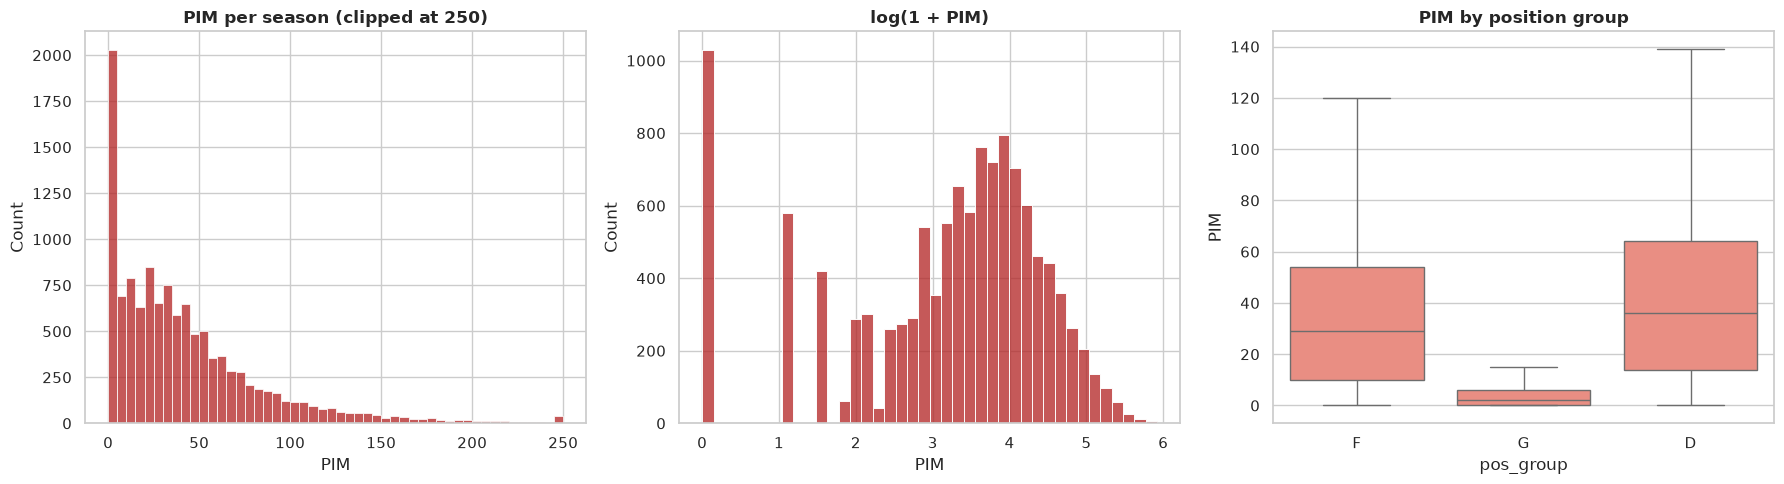

{'count': 11866.0, 'mean': 42.2, 'std': 42.8, 'min': 0.0, '25%': 11.0, '50%': 32.0, '75%': 58.0, 'max': 372.0}
zeros: 8.7% | skew: 1.95 | mean 42.2 vs median 32.0
goalies, mean PIM: 4.26


In [28]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(pe["PIM"].clip(upper=250), bins=50, ax=axes[0], color="firebrick")
axes[0].set_title("PIM per season (clipped at 250)", fontweight="bold")
sns.histplot(np.log1p(pe["PIM"]), bins=40, ax=axes[1], color="firebrick")
axes[1].set_title("log(1 + PIM)", fontweight="bold")
sns.boxplot(data=ps[ps["year"] >= ERA_C], x="pos_group", y="PIM", ax=axes[2], showfliers=False, color="salmon")
axes[2].set_title("PIM by position group", fontweight="bold")
plt.tight_layout()
plt.show()
print(pe["PIM"].describe().round(1).to_dict())
print(f"zeros: {(pe['PIM'] == 0).mean():.1%} | skew: {pe['PIM'].skew():.2f} | mean {pe['PIM'].mean():.1f} vs median {pe['PIM'].median():.1f}")
print("goalies, mean PIM:", round(ps.loc[(ps["pos_group"] == "G") & (ps["year"] >= ERA_C), "PIM"].mean(), 2))

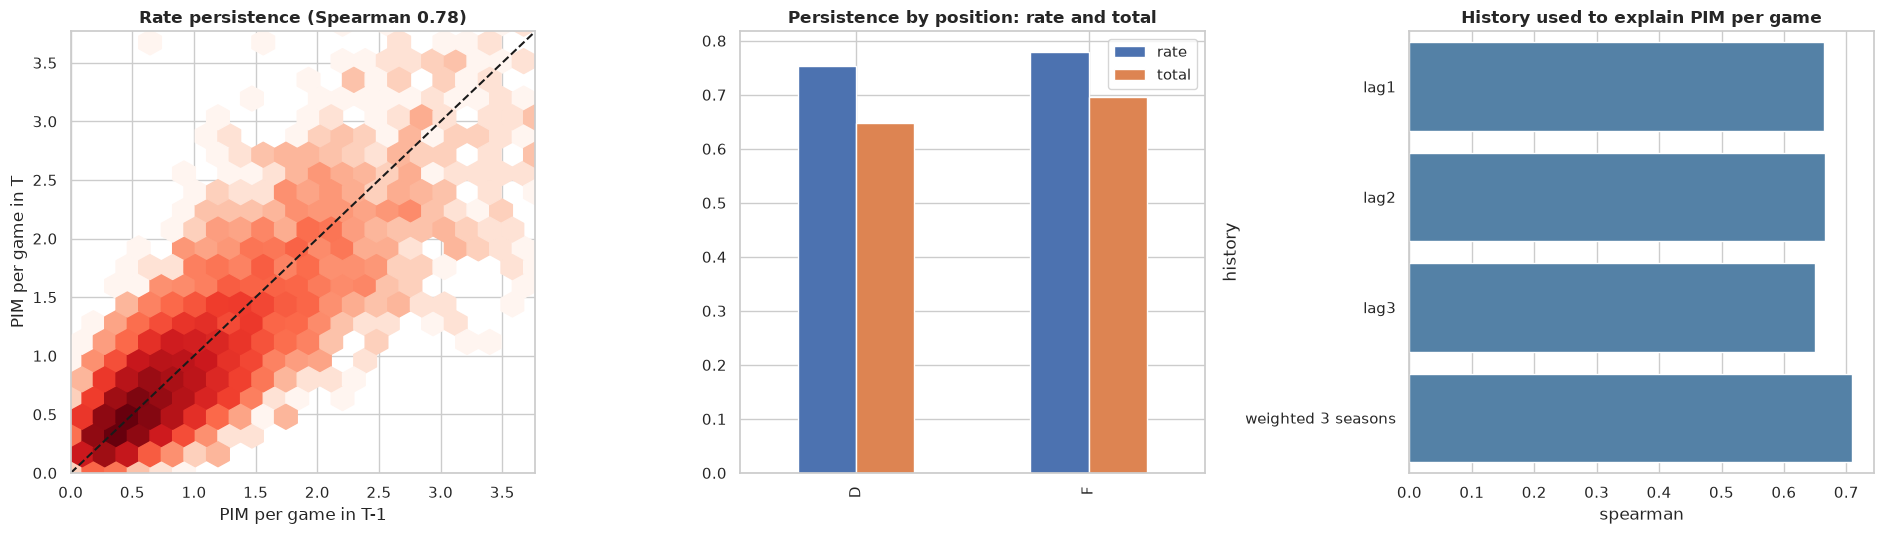

Spearman between games played in T-1 and in T: 0.32
           rate  total       n
pos_group                     
D          0.75   0.65  2606.0
F          0.78   0.70  4833.0


In [29]:
q = pe[(pe["year_gap1"] <= MAX_GAP) & (pe["GP"] >= 20) & (pe["GP_lag1"] >= 20)]
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
axes[0].hexbin(q["pim_pg_lag1"], q["pim_pg"], gridsize=40, cmap="Reds", mincnt=1, bins="log")
lim = float(np.nanpercentile(q["pim_pg"], 99.5))
axes[0].plot([0, lim], [0, lim], "k--")
axes[0].set_xlim(0, lim)
axes[0].set_ylim(0, lim)
axes[0].set_xlabel("PIM per game in T-1")
axes[0].set_ylabel("PIM per game in T")
axes[0].set_title(f"Rate persistence (Spearman {spearman(q['pim_pg_lag1'], q['pim_pg']):.2f})", fontweight="bold")

by_pos = q.groupby("pos_group").apply(lambda d_: pd.Series({"rate": spearman(d_["pim_pg_lag1"], d_["pim_pg"]), "total": spearman(d_["PIM_lag1"], d_["PIM"]), "n": len(d_)}))
by_pos[["rate", "total"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("Persistence by position: rate and total", fontweight="bold")
axes[1].set_xlabel("")

lagrows = [{"history": f"lag{k}", "spearman": spearman(pe["pim_pg"], pe[f"pim_pg_lag{k}"])} for k in (1, 2, 3)]
lagrows.append({"history": "weighted 3 seasons", "spearman": spearman(pe["pim_pg"], pe["pim_pg_w3"])})
sns.barplot(data=pd.DataFrame(lagrows), y="history", x="spearman", ax=axes[2], color="steelblue")
axes[2].set_title("History used to explain PIM per game", fontweight="bold")
plt.tight_layout()
plt.show()
print("Spearman between games played in T-1 and in T:", round(spearman(q["GP_lag1"], q["GP"]), 2))
print(by_pos.round(2))

evaluated on seasons [2005, 2006, 2007, 2008, 2009], players with history: 3534


,MAE,RMSE,bias,Spearman
baseline,,,,
last_season,20.76,30.71,0.18,0.65
avg_2_seasons,19.88,29.31,-0.86,0.66
rate3_x_lastGP,20.41,30.29,0.40,0.66
position_mean,25.99,36.09,-4.41,0.07
global_mean,26.70,35.85,0.18,NaN


players without history: 722 (16.6% of skater-seasons)
MAE of the position mean on them: 31.57


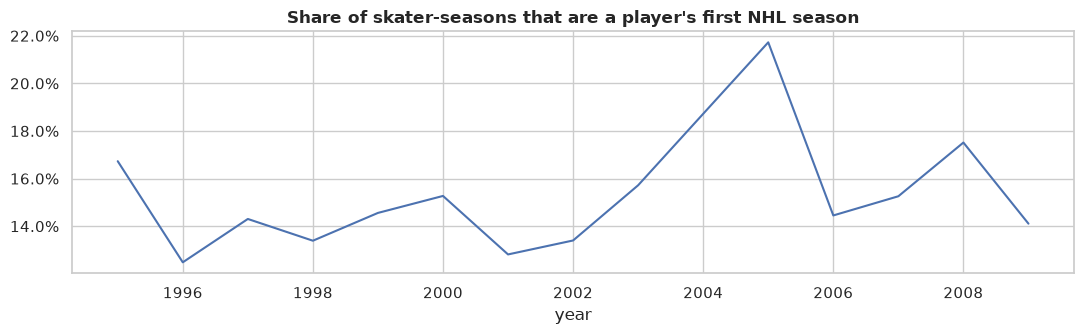

In [30]:
test_years = [int(y) for y in sorted(ps["year"].unique())[-5:]]
ev = ps[ps["year"].isin(test_years) & (ps["pos_group"] != "G")].copy()
hist = ev[ev["PIM_lag1"].notna() & (ev["year_gap1"] <= MAX_GAP)].copy()
hist["last_season"] = hist["PIM_lag1"]
hist["avg_2_seasons"] = hist["pim_avg2"]
hist["rate3_x_lastGP"] = hist["pim_pg_w3"] * hist["GP_lag1"]
hist["position_mean"] = hist["pos_prev_mean"]
hist["global_mean"] = hist["PIM_lag1"].mean()
names = ["last_season", "avg_2_seasons", "rate3_x_lastGP", "position_mean", "global_mean"]
hh = hist.dropna(subset=names + ["PIM"])
rows = [{"baseline": n_, "MAE": (hh[n_] - hh["PIM"]).abs().mean(), "RMSE": np.sqrt(((hh[n_] - hh["PIM"]) ** 2).mean()),
         "bias": (hh[n_] - hh["PIM"]).mean(), "Spearman": spearman(hh[n_], hh["PIM"])} for n_ in names]
print(f"evaluated on seasons {test_years}, players with history: {len(hh)}")
display(pd.DataFrame(rows).set_index("baseline").round(2))

rook = ev[(ev["is_rookie"] == 1) | ev["PIM_lag1"].isna()]
print(f"players without history: {len(rook)} ({len(rook) / len(ev):.1%} of skater-seasons)")
print("MAE of the position mean on them:", round((rook["pos_prev_mean"] - rook["PIM"]).abs().mean(), 2))
share = ps[(ps["year"] >= ERA_C) & (ps["pos_group"] != "G")].groupby("year")["is_rookie"].mean()
fig, ax = plt.subplots(figsize=(11, 3.5))
share.plot(ax=ax)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Share of skater-seasons that are a player's first NHL season", fontweight="bold")
plt.tight_layout()
plt.show()

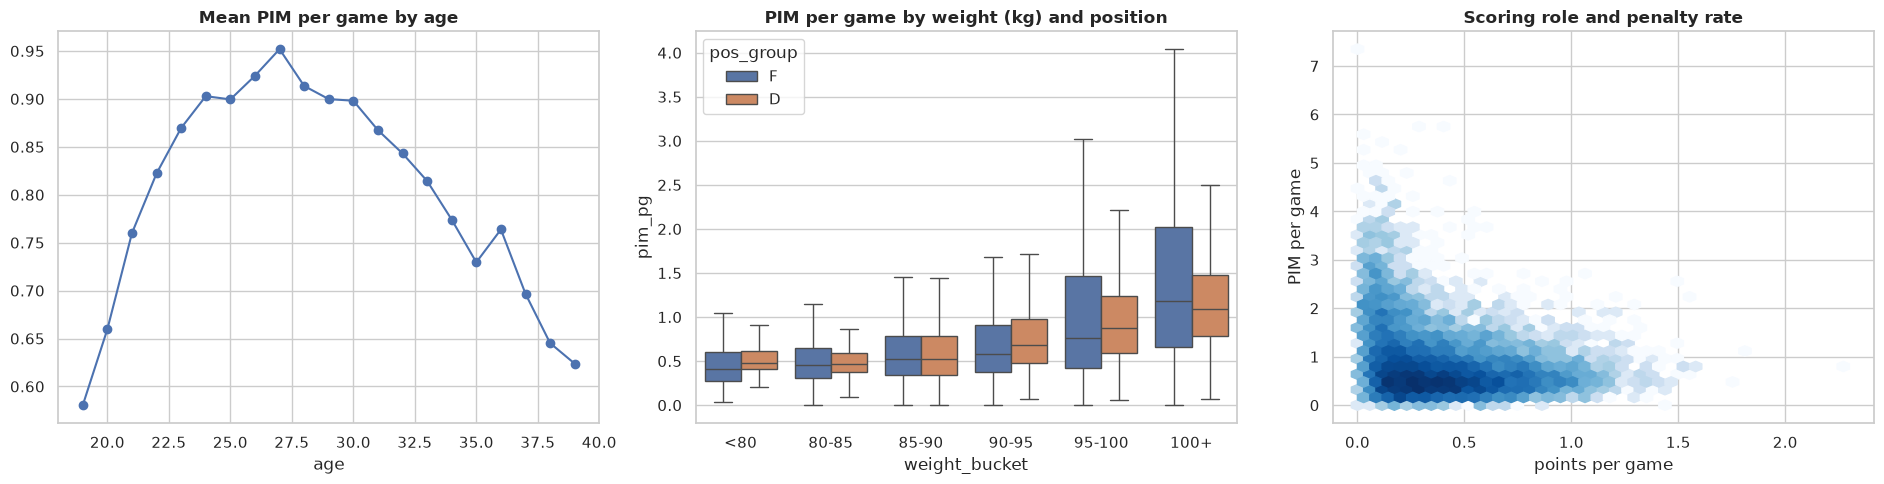

,feature,n,spearman,p_value,decision
0,pim_pg_w3,8394,0.776,0.0000,keep
1,pim_pg_lag1,8394,0.736,0.0000,keep
2,weight,9069,0.396,0.0000,keep
3,height,9069,0.262,0.0000,keep
4,pts_pg_lag1,8394,-0.236,0.0000,keep
5,team_pim_pg_lag1,8394,0.157,0.0000,keep
6,byng_prior,9069,-0.094,0.0000,drop
7,GP_lag1,8394,-0.048,0.0000,drop
8,age,9069,0.040,0.0001,drop
9,awards_prior,9069,-0.037,0.0005,drop


Mean PIM per game, prior Lady Byng winners vs the rest:


,mean,count
byng_prior,,
False,0.861,8994
True,0.353,75


Mean PIM per game by shooting hand:


,mean,count
shootCatch,,
L,0.843,5867
R,0.883,3202


Spearman between the team's PIM per game in T-1 and the player's deviation from his own history: -0.083


In [31]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
a = pe[pe["GP"] >= 20].groupby("age").agg(pim_pg=("pim_pg", "mean"), n=("pim_pg", "size")).query("n >= 30")
a["pim_pg"].plot(ax=axes[0], marker="o")
axes[0].set_title("Mean PIM per game by age", fontweight="bold")
pe["weight_kg"] = pe["weight"] * 0.453592
pe["weight_bucket"] = pd.cut(pe["weight_kg"], [0, 80, 85, 90, 95, 100, 200], labels=["<80", "80-85", "85-90", "90-95", "95-100", "100+"])
sns.boxplot(data=pe[pe["GP"] >= 20].dropna(subset=["weight_bucket"]), x="weight_bucket", y="pim_pg", hue="pos_group", showfliers=False, ax=axes[1])
axes[1].set_title("PIM per game by weight (kg) and position", fontweight="bold")
axes[2].hexbin(pe.loc[pe["GP"] >= 20, "pts_pg"], pe.loc[pe["GP"] >= 20, "pim_pg"], gridsize=40, cmap="Blues", mincnt=1, bins="log")
axes[2].set_xlabel("points per game")
axes[2].set_ylabel("PIM per game")
axes[2].set_title("Scoring role and penalty rate", fontweight="bold")
plt.tight_layout()
plt.show()

tm = team[["tmID", "year", "pim_pg"]].rename(columns={"tmID": "tmID_lag1", "year": "year_lag1", "pim_pg": "team_pim_pg_lag1"})
pe = pe.merge(tm, on=["tmID_lag1", "year_lag1"], how="left")
q2 = pe[pe["GP"] >= 20].copy()
cand_c = [f for f in ["pim_pg_lag1", "pim_pg_w3", "pts_pg_lag1", "GP_lag1", "age", "height", "weight", "awards_prior", "byng_prior", "team_pim_pg_lag1"] if f in q2.columns]
tab_c = spearman_table(q2, cand_c, "pim_pg")
display(tab_c)
print("Mean PIM per game, prior Lady Byng winners vs the rest:")
display(q2.groupby(q2["byng_prior"] > 0)["pim_pg"].agg(["mean", "count"]).round(3))
print("Mean PIM per game by shooting hand:")
display(q2.groupby("shootCatch")["pim_pg"].agg(["mean", "count"]).round(3))
q2["resid_vs_history"] = q2["pim_pg"] - q2["pim_pg_w3"]
print("Spearman between the team's PIM per game in T-1 and the player's deviation from his own history:", round(spearman(q2["team_pim_pg_lag1"], q2["resid_vs_history"]), 3))

### Findings

- The target is skewed and has a spike at zero: 8.7% of skater-seasons have no penalty minutes, the skew is 1.95 and the mean (42.2) sits well above the median (32). Goalies average 4.3 minutes and are a separate population.
- The penalty rate per game is very stable from one season to the next: Spearman 0.78 (0.75 for defensemen, 0.78 for forwards). Season totals are less stable (0.65 and 0.70) because they also depend on games played, which has a Spearman of only 0.32 between consecutive seasons (injuries and roles). Modelling the rate and the expected games separately is therefore preferable to modelling the total.
- Several seasons of history help only a little: lag 1, lag 2 and lag 3 each explain about the same, and a games-weighted average of three seasons is best (0.71 against 0.66 for last season alone).
- Baselines on the last five seasons (2005-2009): the average of the last two seasons has the lowest error (MAE 19.9), followed by the rate over three seasons times last season's games (20.4) and last season alone (20.8). The position average (26.0) and the global average (26.7) are clearly worse. A model has to beat roughly 20 minutes of mean absolute error. Bias is small for the baselines built from the player's own history (between -0.9 and +0.4 minutes), so the downward trend in penalties does not distort them over these five seasons. The position average under-predicts by 4.4 minutes.
- 16.6% of skater-seasons in that period belong to players with no history, and for them the position average has an MAE of 31.6. This group is where most of the remaining error sits, and what we know about them is limited to position, age and physical attributes.
- Physical attributes matter: weight (Spearman 0.40) and height (0.26) are associated with a higher penalty rate. Players who score more take fewer penalties (points per game last season, -0.24). Age (0.04), games played (-0.05) and the number of earlier awards (-0.04) add almost nothing.
- Past Lady Byng winners (a sportsmanship award) average 0.35 PIM per game against 0.86 for everyone else, but there are only 75 such player-seasons and the overall correlation (-0.09) is below the criterion, so the variable is dropped.
- Team context is a weak candidate. The team's penalty rate in the previous season has a Spearman of 0.16 with the player's rate, so it passes the criterion, but its relation with the player's deviation from his own history is small and negative (-0.08). Most of what it carries is already in the player's history.


### 3.5 Preparation decisions

**Time windows**

| Task | From | Reason |
|---|---|---|
| (a) Ranking | 1995 | 82-game seasons, 26-30 teams, all variables complete. Persistence is the same in 1980-1994 and 1995-2004 and weaker after 2005, so recent seasons should weigh more |
| (b) Coach changes | 1990 | rare event (17.7%), so more seasons help, and all the variables used are complete from the late 1980s |
| (c) PIM | 1995 | penalties per game fell steadily until the late 1990s, so older seasons describe a different game |

**Tables**

| Table | Decision | Evidence |
|---|---|---|
| `Teams`, `Coaches`, `Scoring` | core | contain the targets and their main drivers |
| `Master` | use for (c) only | height (0.26) and weight (0.40) relate to the penalty rate; age adds nothing (0.04) and coach age adds nothing for (b) (AUC 0.49) |
| `TeamsPost` | light use for (b) | playoff games played is one of the kept variables in (b); it is redundant for (a) (0.41 raw, 0.03 beyond recent form) |
| `AwardsCoaches` | light use for (b) | prior coach awards are kept (AUC 0.44); the Jack Adams count alone is not |
| `Goalies` | not needed | the main goalie's save percentage adds nothing beyond points for (a) (0.03, p = 0.56) and nothing for (b) (AUC 0.49) |
| `TeamSplits` | not needed | home advantage is unrelated to the ranking (-0.03 beyond recent form) |
| `AwardsPlayers` | not used | prior awards (-0.04) and prior Lady Byng awards (-0.09) fall below the criterion for (c) |
| `TeamVsTeam`, `SeriesPost` | not used | season-level information already in `Teams` and `TeamsPost` |
| `ScoringShootout`, `GoaliesShootout`, `ScoringSup`, `HOF`, `AwardsMisc` | not used | cover a few seasons only or have no link with the targets |

**Variables carried to the models**

- (a) the points % of the last two seasons, weighting the most recent more; goal difference and goals against per game; team penalty minutes per game. The target is the league-wide ranking built from points %.
- (b) points % and goal difference of the last season, playoff games played, prior coach awards. Position in the league and making the playoffs are alternative encodings of the same information.
- (c) the player's penalty rate over the previous three seasons (games-weighted), position, height, weight, points per game, and the team's penalty rate as a weak extra. Players without history are described by position, height and weight only.

**Proposed evaluation criteria (not model evaluation)**: validation is temporal (train on earlier seasons, test on later ones). Scores to beat: Spearman 0.56 for the ranking, average precision above the 17.7% base rate for coach changes, and a mean absolute error of about 20 minutes for PIM (19.9 for the two-season average).


In [32]:
summary = {
    "(a) ranking": keep_a,
    "(b) coach changes": keep_b["feature"].tolist(),
    "(c) PIM per game": tab_c[tab_c["decision"] == "keep"]["feature"].tolist(),
}
for k, v in summary.items():
    print(f"{k}: {', '.join(v) if v else 'none'}")

os.makedirs("processed", exist_ok=True)
team_a.to_csv("processed/team_season.csv", index=False)
cb.to_csv("processed/coach_change_dataset.csv", index=False)
ps.to_csv("processed/player_season.csv", index=False)

(a) ranking: trend_lag1, ga_pg_lag1, pim_pg_lag1, gd_pg_lag1
(b) coach changes: gd_pg_lag1, pts_pct_lag1, post_g_lag1, coach_awards_prior
(c) PIM per game: pim_pg_w3, pim_pg_lag1, weight, height, pts_pg_lag1, team_pim_pg_lag1


## 4. Modeling (M)

In [35]:
from sklearn.linear_model import Ridge, Lasso, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, StackingRegressor, StackingClassifier
import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

features_a = ["trend_lag1", "ga_pg_lag1", "pim_pg_lag1", "gd_pg_lag1"]

base_estimators_a = [
    ('xgb', xgb.XGBRegressor(random_state=42)),
    ('lgb', lgb.LGBMRegressor(random_state=42, verbose=-1)),
    ('rf', RandomForestRegressor(random_state=42))
]

models_a = {
    "XGBoost": xgb.XGBRegressor(random_state=42),
    "LightGBM": lgb.LGBMRegressor(random_state=42, verbose=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0),
    "Stacking Regressor": StackingRegressor(
        estimators=base_estimators_a,
        final_estimator=Ridge(alpha=1.0)
    )
}

features_b = ["gd_pg_lag1", "pts_pct_lag1", "post_g_lag1", "coach_awards_prior"]

base_estimators_b = [
    ('xgb', xgb.XGBClassifier(random_state=42)),
    ('lgb', lgb.LGBMClassifier(random_state=42, verbose=-1)),
    ('rf', RandomForestClassifier(random_state=42))
]

models_b = {
    "Logistic Regression": LogisticRegression(random_state=42),
    "XGBoost Classifier": xgb.XGBClassifier(random_state=42),
    "LightGBM Classifier": lgb.LGBMClassifier(random_state=42, verbose=-1),
    "Random Forest Classifier": RandomForestClassifier(random_state=42),
    "Stacking Classifier": StackingClassifier(
        estimators=base_estimators_b,
        final_estimator=LogisticRegression(random_state=42)
    )
}

features_c = ["pim_pg_w3", "pim_pg_lag1", "weight", "height", "pts_pg_lag1", "team_pim_pg_lag1"]

base_estimators_c = [
    ('rf', RandomForestRegressor(random_state=42)),
    ('xgb', xgb.XGBRegressor(random_state=42))
]

models_c = {
    "Random Forest Regressor": RandomForestRegressor(random_state=42),
    "XGBoost Regressor": xgb.XGBRegressor(random_state=42),
    "Stacking Regressor": StackingRegressor(
        estimators=base_estimators_c,
        final_estimator=Ridge(alpha=1.0)
    )
}

## 5. Evaluation (E)

In [ ]:
import optuna
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.impute import SimpleImputer

def run_sliding_window_pipeline(
    df, 
    start_year, 
    end_year, 
    features, 
    target, 
    models_dict, 
    baseline_dict=None, 
    eval_metric=mean_squared_error,
    year_col='year',
    use_optuna=True,
    n_trials=10
):
    yearly_results = []
    
    # Loop through each evaluation year
    for test_year in range(start_year, end_year + 1):
        print(f"\n---> Processing Evaluation Year: {test_year}")
        
        # Split data chronologically (Training on past, Testing on test_year)
        train_df = df[df[year_col] < test_year]
        test_df = df[df[year_col] == test_year]
        
        if train_df.empty or test_df.empty:
            print(f"Skipping {test_year}: Insufficient train or test data.")
            continue
            
        X_train, y_train = train_df[features], train_df[target]
        X_test, y_test = test_df[features], test_df[target]

        imputer = SimpleImputer(strategy="median")

        # Replaces missing value in training and testing with the median value of each feature.
        X_train = pd.DataFrame(
            imputer.fit_transform(X_train),
            columns=features,
            index=X_train.index
        )

        X_test = pd.DataFrame(
            imputer.transform(X_test),
            columns=features,
            index=X_test.index
        )
        
        row_results = {"year": test_year}
        
        # Evaluate Baselines
        if baseline_dict:
            for b_name, b_pred_func in baseline_dict.items():
                preds = b_pred_func(train_df, test_df, target)
                score = eval_metric(y_test, preds)
                row_results[b_name] = score
        
        # Evaluate Models
        for name, model in models_dict.items():
            # Optional Optuna Tuning per window for tree models
            if use_optuna and name in ["XGBoost", "LightGBM"]:
                best_model = tune_model_with_optuna(name, X_train, y_train, n_trials=n_trials)
            else:
                best_model = model
                best_model.fit(X_train, y_train)
                
            preds = best_model.predict(X_test)
            score = eval_metric(y_test, preds)
            row_results[name] = score
            
        yearly_results.append(row_results)
        
    return pd.DataFrame(yearly_results)


def tune_model_with_optuna(model_name, X_train, y_train, n_trials=10):
    def objective(trial):
        if model_name == "XGBoost":
            params = {
                'max_depth': trial.suggest_int('max_depth', 3, 7),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
                'n_estimators': trial.suggest_int('n_estimators', 50, 200),
                'random_state': 42
            }
            model = xgb.XGBRegressor(**params)
        elif model_name == "LightGBM":
            params = {
                'max_depth': trial.suggest_int('max_depth', 3, 7),
                'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.2),
                'n_estimators': trial.suggest_int('n_estimators', 50, 200),
                'random_state': 42,
                'verbose': -1
            }
            model = lgb.LGBMRegressor(**params)
        else:
            return 0
            
        # Quick internal validation split for Optuna
        split_idx = int(len(X_train) * 0.8)
        X_tr, X_val = X_train.iloc[:split_idx], X_train.iloc[split_idx:]
        y_tr, y_val = y_train.iloc[:split_idx], y_train.iloc[split_idx:]
        
        model.fit(X_tr, y_tr)
        preds = model.predict(X_val)
        return mean_squared_error(y_val, preds)

    study = optuna.create_study(direction='minimize')
    optuna.logging.set_verbosity(optuna.logging.WARNING) # Suppress noisy output
    study.optimize(objective, n_trials=n_trials)
    
    # Train final model on full window using best params
    if model_name == "XGBoost":
        best_model = xgb.XGBRegressor(**study.best_params, random_state=42)
    elif model_name == "LightGBM":
        best_model = lgb.LGBMRegressor(**study.best_params, random_state=42, verbose=-1)
        
    best_model.fit(X_train, y_train)
    return best_model

In [ ]:
def mean_baseline(train_df, test_df, target):
    mean_val = train_df[target].mean()
    return np.full(len(test_df), mean_val)

baselines = {"Historical Mean Baseline": mean_baseline}

performance_df = run_sliding_window_pipeline(
    df = pd.read_csv("processed/team_season.csv"),
    start_year=1995,
    end_year=2004,
    features=features_a,
    target="rank",
    models_dict=models_a,
    baseline_dict=baselines,
    eval_metric=mean_squared_error,
    year_col='year',
    use_optuna=True,
    n_trials=15
)

print(performance_df)


---> Processing Evaluation Year: 1995
Skipping 1995: Insufficient train or test data.

---> Processing Evaluation Year: 1996

---> Processing Evaluation Year: 1997

---> Processing Evaluation Year: 1998

---> Processing Evaluation Year: 1999

---> Processing Evaluation Year: 2000

---> Processing Evaluation Year: 2001

---> Processing Evaluation Year: 2002

---> Processing Evaluation Year: 2003

---> Processing Evaluation Year: 2004
Skipping 2004: Insufficient train or test data.
   year  Historical Mean Baseline   XGBoost  LightGBM  CatBoost  Random Forest     Ridge     Lasso  Stacking Regressor
0  1996                  3.562130  4.008185  3.562130  4.431943       4.078885  3.761110  3.562130            3.649132
1  1997                  3.562130  3.080065  3.545665  3.579612       3.195819  3.008744  3.562130            2.894117
2  1998                  2.813609  3.503718  2.712415  2.834784       2.781546  2.862802  2.813609            2.144785
3  1999                  2.263981  1.7

## 6. Deployment (D)